[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

# Evaluación Parcial — Actividad 1: Pipeline de Machine Learning clásico
## Detección de pacientes con enfermedad hepática (ILPD)

**Curso:** Ingeniería del Conocimiento (ISO56B) · Facultad de Ingeniería de Sistemas · UNCP
**Semestre:** 2026-II · **Fecha:** 21/10/2026
**Docente:** Msc. Jaime Antonio Huaytalla Pariona

---
## A. Presentación

### Integrantes
| N.° | Apellidos y nombres | Código |
|:---:|---|---|
| 1 | Quispe López, Joseph Saúl | 2024200202G |
| 2 | Quispe García, D'Alessandro Del Piero | 2024200201F |
| 3 | Hurtado Pastrana, Sebastián Katsari | 2024200189G |
| 4 | Quiroz Vílchez, Rony Esaú | 2024200200E |

### Dataset
- **Nombre:** ILPD (Indian Liver Patient Dataset)
- **Copia utilizada:** Kaggle — https://www.kaggle.com/datasets/zubairdhuddi/indian-liver-patient-dataset · archivo `Indian Liver Patient Dataset (ILPD).csv`
- **Tamaño:** 583 registros · 10 variables predictoras · 1 variable objetivo (`is_patient`)
- **Aprobación:** dataset aprobado por el docente.

**Justificación de la elección**
- **Relevancia:** Las pruebas de función hepática son exámenes de laboratorio baratos y rutinarios; un modelo que ayude a decidir a quién derivar a evaluación tiene utilidad práctica.
- **Valor didáctico:** desbalance (71.4 % / 28.6 %), valores nulos, duplicados, variables muy asimétricas y encabezados corridos en el CSV, lo que exige un preprocesamiento justificado.

### Descripción del problema
Se busca clasificar si una persona es **paciente hepático (1)** o **no (0)** a partir de su edad, sexo y ocho pruebas de función hepática (bilirrubinas, enzimas ALP/ALT/AST, proteínas totales, albúmina y relación A/G). Es una clasificación binaria supervisada con clases desbalanceadas. En un tamizaje un falso negativo cuesta más que un falso positivo, por eso además de accuracy y F1 macro se vigila el **recall de la clase enfermo**. El trabajo se enmarca en la concientización sobre el daño hepático asociado al alcohol; como ILPD **no registra la causa** de la enfermedad, ese tema se presenta como contexto y no como conclusión del modelo.


---
## B. Carga y Análisis Exploratorio de Datos (EDA)

### B.1 Configuración del entorno

In [ ]:
# B.1  Librerías y configuración general
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score, precision_score,
    recall_score, f1_score, roc_curve, roc_auc_score, precision_recall_curve
)

# imbalanced-learn (SMOTE) viene en Colab; si faltara, se instala
try:
    import imblearn
except ImportError:
    !pip install -q imbalanced-learn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Estilo de gráficos
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

# Colores fijos: azul = Sano, naranja = Enfermo (paleta apta para daltonismo)
COLOR_SANO, COLOR_ENFERMO = '#2a78d6', '#eb6834'
COLORES_MODELOS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']

RANDOM_STATE = 42   # semilla fija para que todo sea reproducible
print('✓ Librerías cargadas correctamente')

✓ Librerías cargadas correctamente


### B.2 Carga del dataset
El CSV se busca en este orden: **(1)** en la carpeta de trabajo de Colab, **(2)** descargándolo directamente desde la URL de Kaggle con `kagglehub` (dataset público) y **(3)** si ambas fallan, se pide subir el archivo manualmente.

In [ ]:
# B.2  Carga del dataset
ARCHIVO = 'Indian Liver Patient Dataset (ILPD).csv'
KAGGLE_ID = 'zubairdhuddi/indian-liver-patient-dataset'   # kaggle.com/datasets/<KAGGLE_ID>

def ubicar_csv():
    '''Devuelve la ruta del CSV: archivo local -> descarga de Kaggle -> subida manual.'''
    # 1) ¿El archivo ya está en la carpeta de trabajo?
    if os.path.exists(ARCHIVO):
        return ARCHIVO
    # 2) Descarga directa desde Kaggle
    try:
        import kagglehub
        carpeta = kagglehub.dataset_download(KAGGLE_ID)
        return glob.glob(os.path.join(carpeta, '**', '*.csv'), recursive=True)[0]
    except Exception as e:
        print('No se pudo descargar desde Kaggle:', e)
    # 3) Último recurso: subir el archivo desde la PC
    from google.colab import files
    subido = files.upload()
    return list(subido.keys())[0]

ruta_csv = ubicar_csv()
df_raw = pd.read_csv(ruta_csv)
print(f'Archivo cargado: {ruta_csv}')
print(f'Dataset: {df_raw.shape[0]} filas × {df_raw.shape[1]} columnas')

100%|██████████| 7.65k/7.65k [00:00<00:00, 5.49MB/s]

Extracting files...
Archivo cargado: /root/.cache/kagglehub/datasets/zubairdhuddi/indian-liver-patient-dataset/versions/1/Indian Liver Patient Dataset (ILPD).csv
Dataset: 583 filas × 11 columnas


In [ ]:
# B.3  Paso 0 — ¿El dataset cumple los requisitos mínimos de la consigna (Sección 1.2)?
n_filas, n_cols = df_raw.shape
n_features = n_cols - 1                         # se excluye la variable objetivo
clases = sorted(int(c) for c in df_raw['is_patient'].unique())  # se espera [1, 2]

requisitos = {
    '(a) Objetivo discreto (clasificación)': df_raw['is_patient'].dtype.kind in 'iu',
    '(b) Al menos 500 registros':            n_filas >= 500,
    '(b) Al menos 5 features':               n_features >= 5,
    '(c) Al menos 2 clases':                 len(clases) >= 2,
}
for req, ok in requisitos.items():
    print(f"{'✓' if ok else '✗'} {req}")
print(f'\nFilas: {n_filas} | Features: {n_features} | Clases: {clases}')

# (d) Datos reales: la copia de Kaggle debe reproducir los conteos publicados por UCI
print('\nComparación con UCI (416 enfermos / 167 sanos; 441 hombres / 142 mujeres):')
print(df_raw['is_patient'].value_counts().to_dict(), df_raw['gender'].value_counts().to_dict())
# (e) "No usado en clase" no se verifica con código: se justifica en la Sección A

✓ (a) Objetivo discreto (clasificación)
✓ (b) Al menos 500 registros
✓ (b) Al menos 5 features
✓ (c) Al menos 2 clases

Filas: 583 | Features: 10 | Clases: [1, 2]

Comparación con UCI (416 enfermos / 167 sanos; 441 hombres / 142 mujeres):
{1: 416, 2: 167} {'Male': 441, 'Female': 142}


In [ ]:
# B.4  Primeras filas, dimensiones y tipos de datos
display(df_raw.head())
print(f'Shape: {df_raw.shape}\n')
print('Tipos de datos:')
print(df_raw.dtypes)

,age,gender,tot_bilirubin,direct_bilirubin,tot_proteins,albumin,ag_ratio,sgpt,sgot,alkphos,is_patient
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


Shape: (583, 11)

Tipos de datos:
age                   int64
gender               object
tot_bilirubin       float64
direct_bilirubin    float64
tot_proteins          int64
albumin               int64
ag_ratio              int64
sgpt                float64
sgot                float64
alkphos             float64
is_patient            int64
dtype: object


In [ ]:
# B.5  Valores nulos y filas duplicadas
nulos = df_raw.isna().sum()
print('Valores nulos por columna (nombres tal como vienen en el CSV):')
print(nulos[nulos > 0])
print(f'\nTotal de nulos: {nulos.sum()}  ({nulos.sum() / len(df_raw):.1%} de las filas)')
print(f'Filas duplicadas exactas: {df_raw.duplicated().sum()}')

Valores nulos por columna (nombres tal como vienen en el CSV):
alkphos    4
dtype: int64

Total de nulos: 4  (0.7% de las filas)
Filas duplicadas exactas: 13


### B.6 Evidencia de encabezados corridos

El CSV de Kaggle tiene **seis encabezados desplazados**: el orden real de las columnas es el de UCI (`age, gender, TB, DB, Alkphos, Sgpt, Sgot, TP, ALB, A/G, Selector`), pero los nombres están en otro orden. Basta comparar los valores con los **rangos clínicos de referencia** (orientativos, adultos):

| Variable | Unidad | Rango de referencia aprox. |
|---|---|---|
| Bilirrubina total | mg/dL | 0.1 – 1.2 |
| Bilirrubina directa | mg/dL | 0.0 – 0.3 |
| Fosfatasa alcalina (ALP) | U/L | 40 – 150 |
| ALT (SGPT) | U/L | 7 – 56 |
| AST (SGOT) | U/L | 10 – 40 |
| Proteínas totales | g/dL | 6.0 – 8.3 |
| Albúmina | g/dL | 3.5 – 5.0 |
| Relación A/G | — | 1.0 – 2.5 |

En el `describe()` de abajo, la columna llamada **`albumin`** llega a **2000** (imposible en g/dL: es la escala de una enzima), la columna llamada **`alkphos`** va de **0.3 a 2.8** (es la escala de un cociente, como A/G) y **`sgpt`/`sgot`** tienen valores entre 1 y 10 (escala de proteínas y albúmina en g/dL). Además tienen 4 nulos en `alkphos`, que según UCI corresponden a la relación A/G.

In [ ]:
# B.6  describe() con los nombres ORIGINALES del CSV (evidencia del problema)
df_raw.describe().T[['mean', 'min', '50%', 'max']].round(2)

,mean,min,50%,max
age,44.75,4.0,45.00,90.0
tot_bilirubin,3.30,0.4,1.00,75.0
direct_bilirubin,1.49,0.1,0.30,19.7
tot_proteins,290.58,63.0,208.00,2110.0
albumin,80.71,10.0,35.00,2000.0
ag_ratio,109.91,10.0,42.00,4929.0
sgpt,6.48,2.7,6.60,9.6
sgot,3.14,0.9,3.10,5.5
alkphos,0.95,0.3,0.93,2.8
is_patient,1.29,1.0,1.00,2.0


In [ ]:
# B.7  Corrección de encabezados con rename
# El rename con diccionario cambia todos los nombres a la vez (no en cadena),
# por eso se pueden "intercambiar" nombres sin pisarse entre sí.
CORRECCION = {
    'tot_proteins': 'alkphos',       # valores 63–2110 U/L   -> fosfatasa alcalina
    'albumin':      'sgpt',          # valores 10–2000 U/L   -> ALT
    'ag_ratio':     'sgot',          # valores 10–4929 U/L   -> AST
    'sgpt':         'tot_proteins',  # valores 2.7–9.6 g/dL  -> proteínas totales
    'sgot':         'albumin',       # valores 0.9–5.5 g/dL  -> albúmina
    'alkphos':      'ag_ratio',      # valores 0.3–2.8       -> relación A/G
}
df = df_raw.rename(columns=CORRECCION)
print('Columnas corregidas:', list(df.columns))

Columnas corregidas: ['age', 'gender', 'tot_bilirubin', 'direct_bilirubin', 'alkphos', 'sgpt', 'sgot', 'tot_proteins', 'albumin', 'ag_ratio', 'is_patient']


In [ ]:
# B.8  Verificación de la corrección
# (1) Rangos: ahora cada variable debe estar en la escala clínica que le corresponde
verif = df.describe().T[['min', '50%', 'max']].round(2)
display(verif.drop('is_patient'))
assert df['albumin'].max() < 10 and df['tot_proteins'].max() < 15 and df['ag_ratio'].max() < 5

# (2) Coherencia interna: A/G = albúmina / globulina = ALB / (TP − ALB)
def diferencia_ag(datos, alb, tp, ag):
    '''Mediana de |A/G calculada − A/G registrada| usando las columnas indicadas.'''
    calc = datos[alb] / (datos[tp] - datos[alb])
    return (calc - datos[ag]).abs().median()

print(f"Con nombres ORIGINALES : mediana |A/G calc − A/G| = "
      f"{diferencia_ag(df_raw, 'albumin', 'tot_proteins', 'ag_ratio'):.3f}")
print(f"Con nombres CORREGIDOS : mediana |A/G calc − A/G| = "
      f"{diferencia_ag(df, 'albumin', 'tot_proteins', 'ag_ratio'):.3f}")

# (3) Consistencia: la bilirrubina directa no debería superar a la total
print(f'\nFilas con bilirrubina directa > total: {(df.direct_bilirubin > df.tot_bilirubin).sum()}')

,min,50%,max
age,4.0,45.00,90.0
tot_bilirubin,0.4,1.00,75.0
direct_bilirubin,0.1,0.30,19.7
alkphos,63.0,208.00,2110.0
sgpt,10.0,35.00,2000.0
sgot,10.0,42.00,4929.0
tot_proteins,2.7,6.60,9.6
albumin,0.9,3.10,5.5
ag_ratio,0.3,0.93,2.8


Con nombres ORIGINALES : mediana |A/G calc − A/G| = 41.377
Con nombres CORREGIDOS : mediana |A/G calc − A/G| = 0.031

Filas con bilirrubina directa > total: 3


**Resultado:** con los nombres corregidos todas las variables caen en su escala clínica y la relación A/G recalculada como `ALB / (TP − ALB)` coincide con la registrada (diferencia mediana ≈ 0.03, atribuible al redondeo), mientras que con los nombres originales la fórmula no tiene sentido. La corrección queda **confirmada por dos vías independientes**. Se detectan además 3 filas con bilirrubina directa mayor que la total (posible error de registro); al ser solo 3 se conservan y se mencionan como limitación.

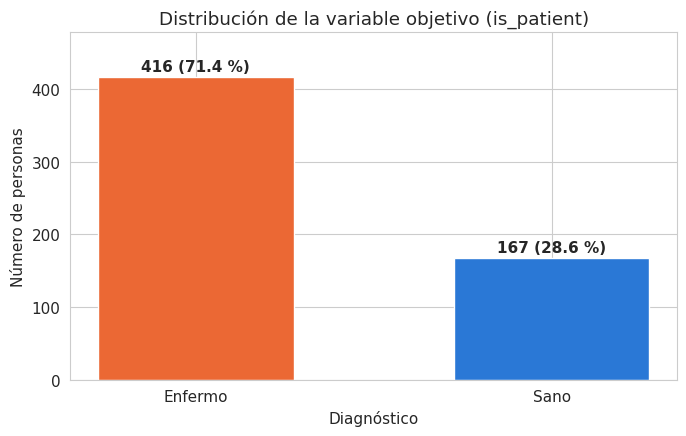

In [ ]:
# B.9  Distribución de la variable objetivo (conteo y porcentaje)
df['diagnostico'] = df['is_patient'].map({1: 'Enfermo', 2: 'Sano'})   # solo para gráficos
conteo = df['diagnostico'].value_counts().reindex(['Enfermo', 'Sano'])
porcentaje = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(conteo.index, conteo.values, color=[COLOR_ENFERMO, COLOR_SANO], width=0.55)
for barra, n, p in zip(barras, conteo.values, porcentaje.values):
    ax.text(barra.get_x() + barra.get_width() / 2, n + 5, f'{n} ({p:.1f} %)',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_title('Distribución de la variable objetivo (is_patient)')
ax.set_xlabel('Diagnóstico')
ax.set_ylabel('Número de personas')
ax.set_ylim(0, conteo.max() * 1.15)
plt.tight_layout()
plt.show()

In [ ]:
# B.10  Estadísticas descriptivas de las variables numéricas (nombres corregidos)
NUMERICAS = ['age', 'tot_bilirubin', 'direct_bilirubin', 'alkphos', 'sgpt',
             'sgot', 'tot_proteins', 'albumin', 'ag_ratio']
desc = df[NUMERICAS].describe().T
desc['asimetria'] = df[NUMERICAS].skew()       # > 1 indica cola larga a la derecha
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria
age,583.0,44.75,16.19,4.0,33.0,45.00,58.0,90.0,-0.03
tot_bilirubin,583.0,3.30,6.21,0.4,0.8,1.00,2.6,75.0,4.91
direct_bilirubin,583.0,1.49,2.81,0.1,0.2,0.30,1.3,19.7,3.21
alkphos,583.0,290.58,242.94,63.0,175.5,208.00,298.0,2110.0,3.77
sgpt,583.0,80.71,182.62,10.0,23.0,35.00,60.5,2000.0,6.55
sgot,583.0,109.91,288.92,10.0,25.0,42.00,87.0,4929.0,10.55
tot_proteins,583.0,6.48,1.09,2.7,5.8,6.60,7.2,9.6,-0.29
albumin,583.0,3.14,0.80,0.9,2.6,3.10,3.8,5.5,-0.04
ag_ratio,579.0,0.95,0.32,0.3,0.7,0.93,1.1,2.8,0.99


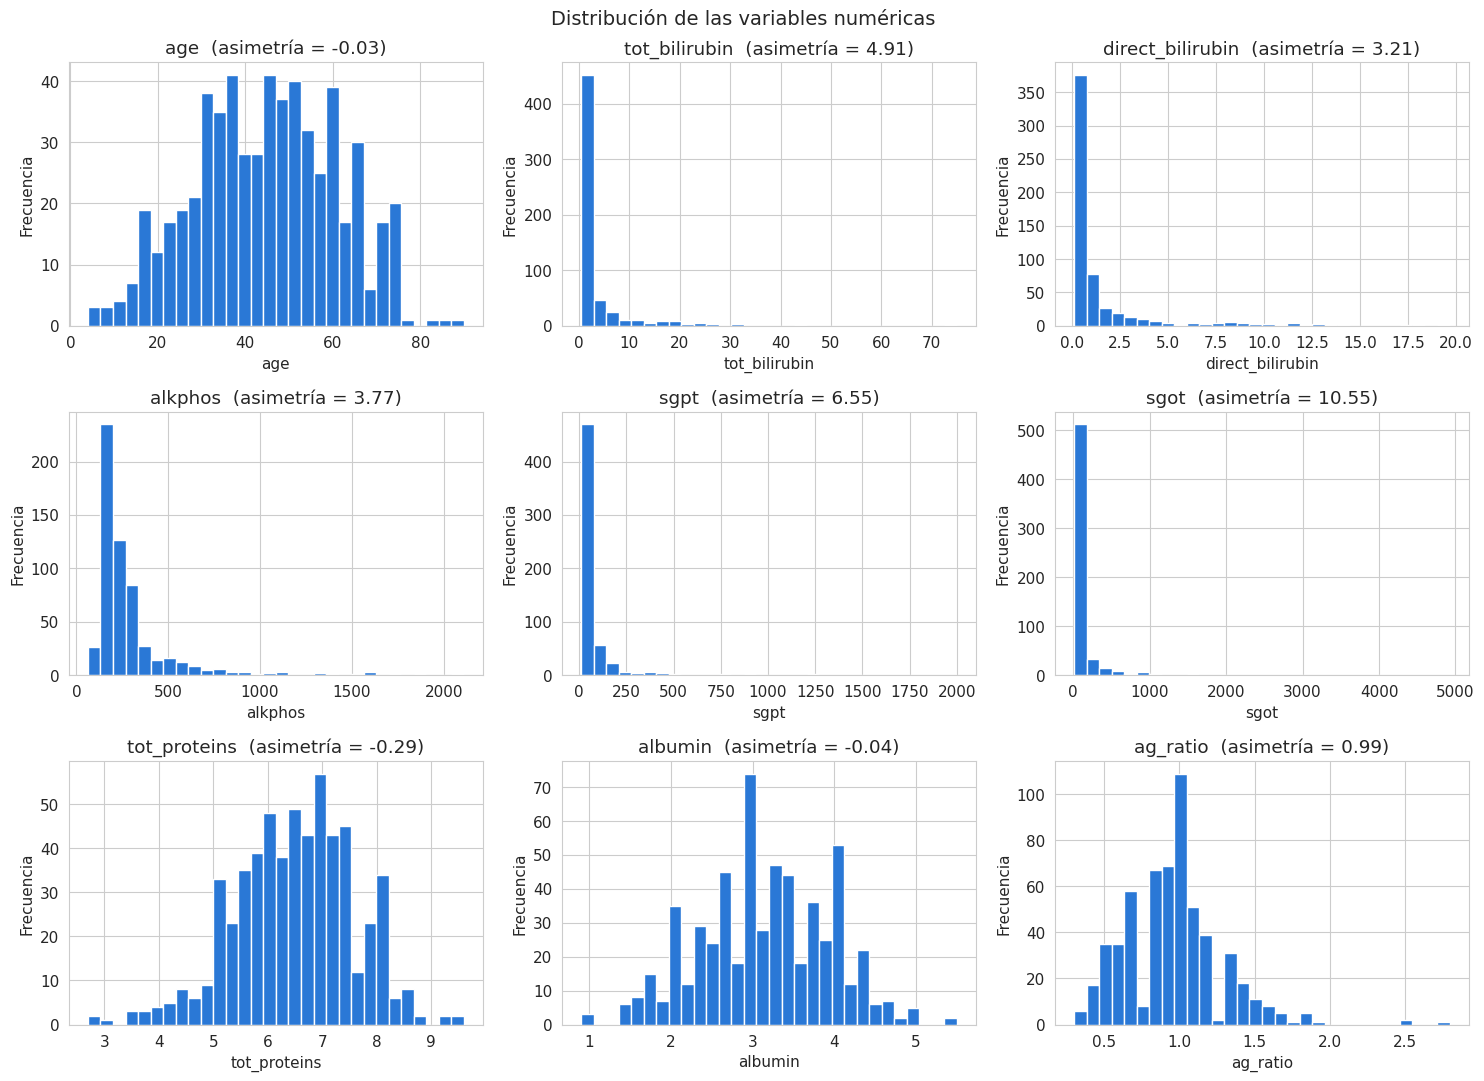

In [ ]:
# B.11  Visualización 1 — Histogramas de las variables numéricas
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), NUMERICAS):
    ax.hist(df[col].dropna(), bins=30, color='#2a78d6', edgecolor='white')
    ax.set_title(f'{col}  (asimetría = {df[col].skew():.2f})')
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')
plt.suptitle('Distribución de las variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

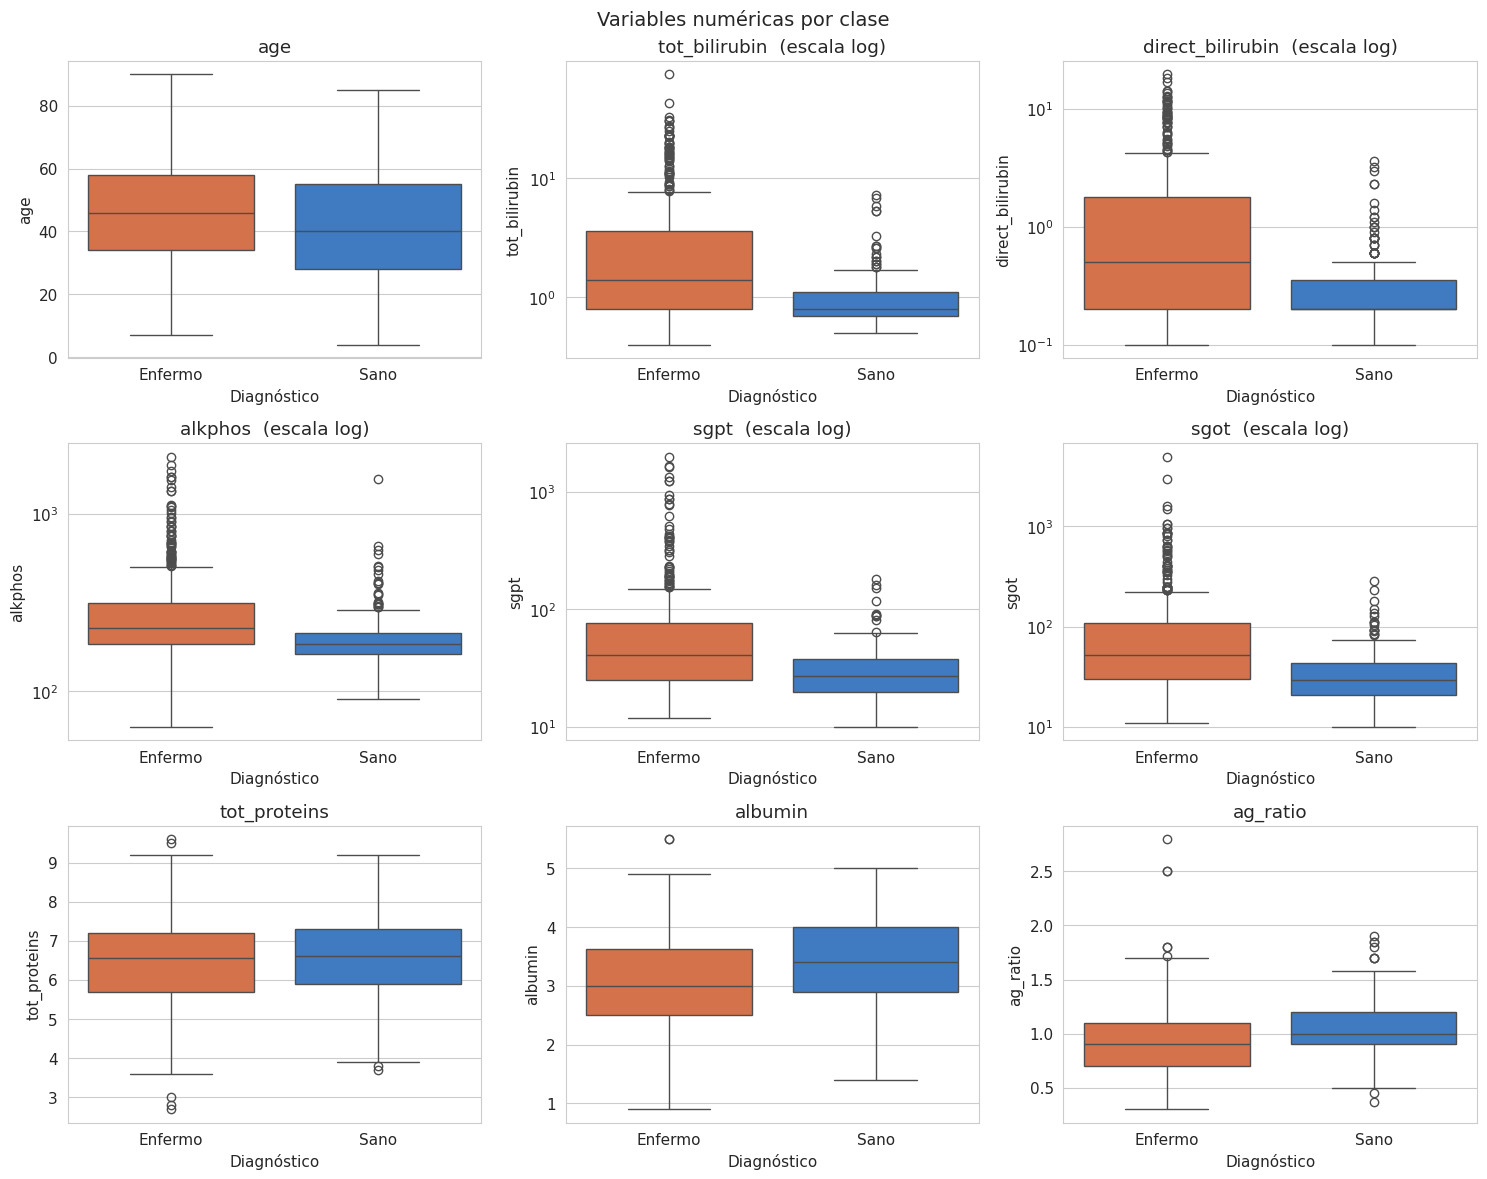

In [ ]:
# B.12  Visualización 2 — Boxplots por clase (escala log en las variables asimétricas)
ASIMETRICAS = ['tot_bilirubin', 'direct_bilirubin', 'alkphos', 'sgpt', 'sgot']
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.ravel(), NUMERICAS):
    sns.boxplot(data=df, x='diagnostico', y=col, order=['Enfermo', 'Sano'],
                palette=[COLOR_ENFERMO, COLOR_SANO], ax=ax)
    if col in ASIMETRICAS:
        ax.set_yscale('log')
    ax.set_title(col + ('  (escala log)' if col in ASIMETRICAS else ''))
    ax.set_xlabel('Diagnóstico')
    ax.set_ylabel(col)
plt.suptitle('Variables numéricas por clase', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# B.13  Cantidad de outliers por variable (criterio IQR: fuera de Q1−1.5·IQR, Q3+1.5·IQR)
q1, q3 = df[NUMERICAS].quantile(0.25), df[NUMERICAS].quantile(0.75)
iqr = q3 - q1
outliers = ((df[NUMERICAS] < q1 - 1.5 * iqr) | (df[NUMERICAS] > q3 + 1.5 * iqr)).sum()
pd.DataFrame({'outliers': outliers, '% filas': (outliers / len(df) * 100).round(1)})

,outliers,% filas
age,0,0.0
tot_bilirubin,84,14.4
direct_bilirubin,81,13.9
alkphos,69,11.8
sgpt,73,12.5
sgot,66,11.3
tot_proteins,8,1.4
albumin,0,0.0
ag_ratio,10,1.7


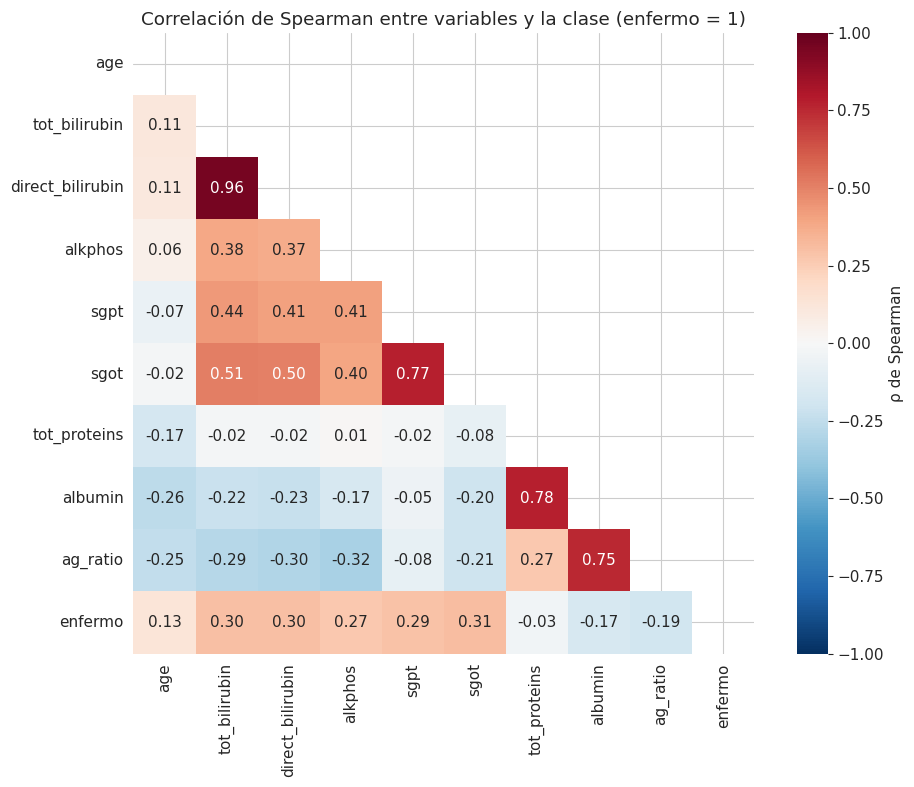

Correlación con la clase "enfermo" (ordenada):
sgot                0.309
tot_bilirubin       0.304
direct_bilirubin    0.297
sgpt                0.291
alkphos             0.273
age                 0.130
tot_proteins       -0.032
albumin            -0.167
ag_ratio           -0.189
Name: enfermo, dtype: float64


In [ ]:
# B.14  Visualización 3 — Mapa de calor de correlación (Spearman)
# Se usa Spearman (basada en rangos) porque las enzimas son muy asimétricas y tienen outliers
df_corr = df[NUMERICAS].copy()
df_corr['enfermo'] = (df['is_patient'] == 1).astype(int)
corr = df_corr.corr(method='spearman')

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, cbar_kws={'label': 'ρ de Spearman'})
plt.title('Correlación de Spearman entre variables y la clase (enfermo = 1)')
plt.tight_layout()
plt.show()

print('Correlación con la clase "enfermo" (ordenada):')
print(corr['enfermo'].drop('enfermo').sort_values(ascending=False).round(3))

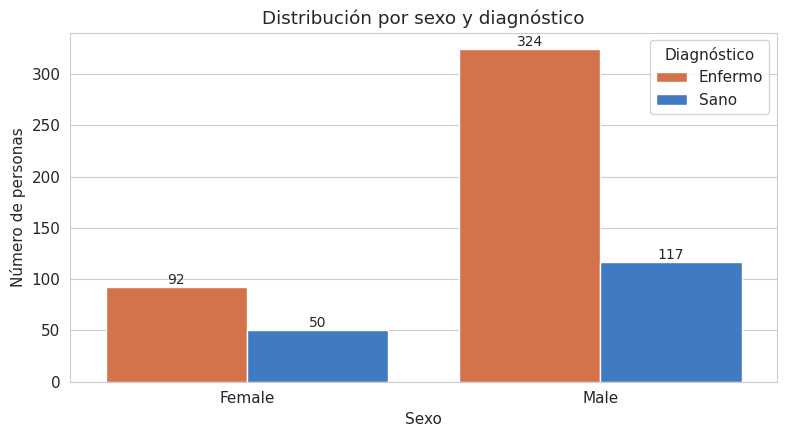

% de enfermos por sexo:
gender
Female    64.8
Male      73.5
Name: is_patient, dtype: float64


In [ ]:
# B.15  Visualización 4 — Sexo por clase (conteo y % de enfermos dentro de cada sexo)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, x='gender', hue='diagnostico', hue_order=['Enfermo', 'Sano'],
              palette=[COLOR_ENFERMO, COLOR_SANO], ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fontsize=10)
ax.set_title('Distribución por sexo y diagnóstico')
ax.set_xlabel('Sexo')
ax.set_ylabel('Número de personas')
ax.legend(title='Diagnóstico')
plt.tight_layout()
plt.show()

print('% de enfermos por sexo:')
print((df.groupby('gender')['is_patient'].apply(lambda s: (s == 1).mean() * 100)).round(1))

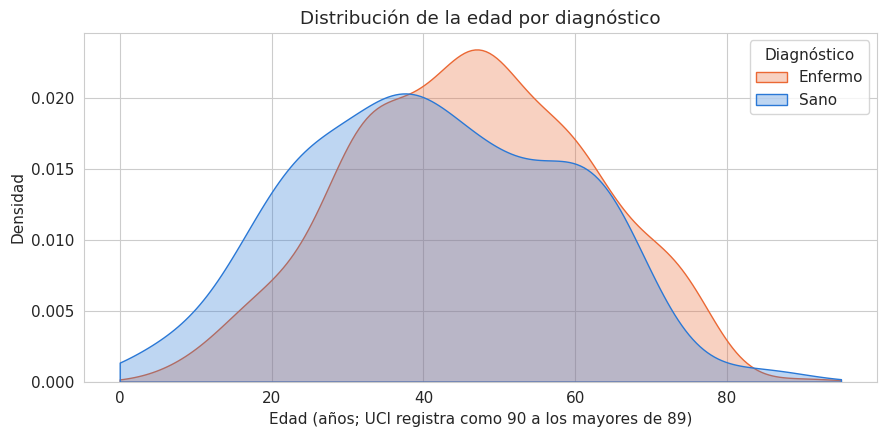

In [ ]:
# B.16  Visualización 5 — Edad por clase
fig, ax = plt.subplots(figsize=(9, 4.5))
for etiqueta, color in [('Enfermo', COLOR_ENFERMO), ('Sano', COLOR_SANO)]:
    sns.kdeplot(df.loc[df['diagnostico'] == etiqueta, 'age'], fill=True, alpha=0.3,
                color=color, label=etiqueta, clip=(0, 95), ax=ax)
ax.set_title('Distribución de la edad por diagnóstico')
ax.set_xlabel('Edad (años; UCI registra como 90 a los mayores de 89)')
ax.set_ylabel('Densidad')
ax.legend(title='Diagnóstico')
plt.tight_layout()
plt.show()

### Conclusiones del EDA
El dataset tiene 583 registros y 11 columnas; seis encabezados venían corridos y se corrigieron, con verificación por rangos clínicos y por la fórmula A/G. La clase objetivo está **desbalanceada** (71.4 % enfermos / 28.6 % sanos): un modelo que diga siempre "enfermo" ya acierta ~71 %, así que se usará split estratificado, **F1 macro y AUC** como métricas principales y se probarán `class_weight` y SMOTE. Las bilirrubinas y las enzimas (ALP, ALT, AST) tienen asimetrías de 3 a 10 y entre 11 % y 14 % de outliers IQR, pero son valores clínicamente posibles y son justamente las variables más asociadas a la enfermedad (ρ ≈ 0.27–0.31): se **conservan** y se transforman con **log1p + StandardScaler** (no MinMax, que se distorsiona con outliers). La albúmina y la relación A/G son menores en los enfermos (ρ ≈ −0.17 y −0.19). Hay pares muy correlacionados (bilirrubina total–directa ρ = 0.96; ALT–AST 0.77; proteínas–albúmina 0.78), lo que recomienda modelos con regularización. Solo hay **4 nulos** (0.7 %, en A/G) → imputación por **mediana** dentro del Pipeline; **13 duplicados** → se eliminan antes del split; `gender` (75.6 % hombres) → **one-hot**; y el objetivo se recodifica a **1 = enfermo, 0 = sano**.

---
## C. Preprocesamiento

Los pasos que **no aprenden nada de los datos** (eliminar duplicados, recodificar el objetivo) se hacen antes del split. Todo lo que **aprende parámetros** (mediana para imputar, media y desviación para escalar, categorías del one-hot) se mete en un `Pipeline` + `ColumnTransformer`, para que se ajuste **solo con train** dentro de cada fold y en el entrenamiento final. Así se evita el *data leakage*.

In [ ]:
# C.1  Eliminación de duplicados (antes del split)
# Si una fila y su copia quedaran una en train y otra en test, el modelo sería evaluado
# con un registro que ya "vio": eso inflaría las métricas (fuga de información).
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Filas: {n_antes} -> {len(df)}  (eliminados {n_antes - len(df)} duplicados)')
print(f"Proporción tras eliminar: {(df['is_patient'] == 1).mean():.1%} enfermos")

Filas: 583 -> 570  (eliminados 13 duplicados)
Proporción tras eliminar: 71.2% enfermos


In [ ]:
# C.2  Recodificación de la variable objetivo: 1 = enfermo, 0 = sano
# (el CSV usa 1 = enfermo y 2 = sano; scikit-learn espera 1 = clase positiva)
df['target'] = (df['is_patient'] == 1).astype(int)
print(pd.crosstab(df['is_patient'], df['target'], rownames=['is_patient (original)'],
                  colnames=['target (nuevo)']))
print('\nValores de gender:', list(df['gender'].unique()), '-> se codificará con OneHotEncoder en el Pipeline')

target (nuevo)           0    1
is_patient (original)          
1                        0  406
2                      164    0

Valores de gender: ['Female', 'Male'] -> se codificará con OneHotEncoder en el Pipeline


In [ ]:
# C.3  Grupos de variables según el tratamiento que recibirán
LOG_COLS = ['tot_bilirubin', 'direct_bilirubin', 'alkphos', 'sgpt', 'sgot']  # muy asimétricas
LIN_COLS = ['age', 'tot_proteins', 'albumin', 'ag_ratio']                     # aprox. simétricas
CAT_COLS = ['gender']                                                         # categórica

X = df[LOG_COLS + LIN_COLS + CAT_COLS].copy()
y = df['target'].copy()
print(f'X: {X.shape}  |  y: {y.shape}')

X: (570, 10)  |  y: (570,)


In [ ]:
# C.4  División train/test estratificada (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Verificación: la proporción de clases debe ser casi igual en total, train y test
verif_split = pd.DataFrame({
    'n': [len(y), len(y_train), len(y_test)],
    '% enfermo': [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
    '% sano': [(1 - y.mean()) * 100, (1 - y_train.mean()) * 100, (1 - y_test.mean()) * 100],
}, index=['Total', 'Train', 'Test']).round(1)
verif_split

,n,% enfermo,% sano
Total,570,71.2,28.8
Train,456,71.3,28.7
Test,114,71.1,28.9


### Justificación del preprocesamiento

| Paso | Decisión | Por qué |
|---|---|---|
| Nulos (4 en `ag_ratio`, 0.7 %) | `SimpleImputer(strategy='median')` | Son muy pocos; eliminarlos perdería datos y la **mediana** es robusta a la asimetría. Se ajusta solo con train. |
| Codificación de `gender` | `OneHotEncoder(drop='if_binary')` | Variable nominal de 2 valores → una sola columna 0/1, sin orden artificial. `handle_unknown='ignore'` protege ante valores nuevos. |
| Transformación log | `FunctionTransformer(np.log1p)` en bilirrubinas y enzimas | Asimetrías de 3 a 10; el log comprime la cola y acerca la distribución a la normal. `log1p` = log(1 + x) evita problemas con valores cercanos a 0. |
| Escalado | `StandardScaler` (no `MinMaxScaler`) | Con outliers extremos (AST hasta 4929), MinMax aplastaría a casi todos los pacientes cerca de 0; StandardScaler tras el log deja media 0 y desviación 1. LR, SVM y KNN dependen de distancias o de la magnitud de los coeficientes. |
| Outliers | Se **conservan** | Son valores clínicamente posibles (hepatitis aguda) y justamente los más informativos de enfermedad; el log reduce su influencia. |
| Árboles / Random Forest | Sin log ni escalado | Las particiones por umbral no cambian con transformaciones monótonas. |

In [ ]:
# C.5  ColumnTransformer para modelos sensibles a la escala (LR, SVM, KNN)
transf_log = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler()),
])
transf_lin = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
transf_cat = OneHotEncoder(drop='if_binary', handle_unknown='ignore')

preprocess_scaled = ColumnTransformer([
    ('log', transf_log, LOG_COLS),
    ('lin', transf_lin, LIN_COLS),
    ('cat', transf_cat, CAT_COLS),
])

# C.6  ColumnTransformer para árboles (solo imputación + codificación)
preprocess_tree = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), LOG_COLS + LIN_COLS),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), CAT_COLS),
])
print('ColumnTransformers definidos: preprocess_scaled (LR/SVM/KNN) y preprocess_tree (árboles)')

ColumnTransformers definidos: preprocess_scaled (LR/SVM/KNN) y preprocess_tree (árboles)


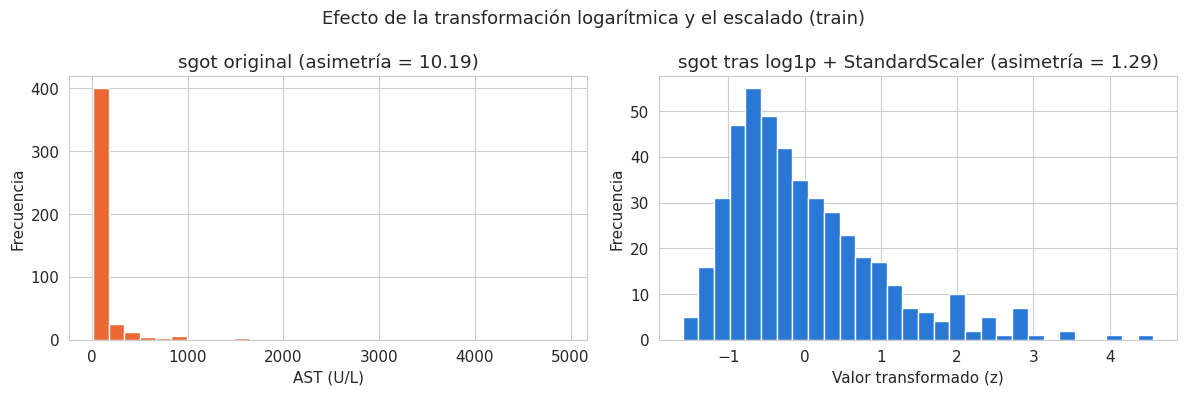

Medias tras el preprocesamiento (≈ 0) y desviaciones (≈ 1) en train:
                       mean  std
log__tot_bilirubin      0.0  1.0
log__direct_bilirubin   0.0  1.0
log__alkphos           -0.0  1.0
log__sgpt               0.0  1.0
log__sgot              -0.0  1.0
lin__age               -0.0  1.0
lin__tot_proteins       0.0  1.0
lin__albumin            0.0  1.0
lin__ag_ratio          -0.0  1.0


In [ ]:
# C.7  Efecto del preprocesamiento (ajustado SOLO con train) sobre una variable asimétrica
X_train_prep = pd.DataFrame(preprocess_scaled.fit_transform(X_train),
                            columns=preprocess_scaled.get_feature_names_out())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train['sgot'], bins=30, color=COLOR_ENFERMO, edgecolor='white')
axes[0].set_title(f"sgot original (asimetría = {X_train['sgot'].skew():.2f})")
axes[0].set_xlabel('AST (U/L)')
axes[0].set_ylabel('Frecuencia')
axes[1].hist(X_train_prep['log__sgot'], bins=30, color=COLOR_SANO, edgecolor='white')
axes[1].set_title(f"sgot tras log1p + StandardScaler (asimetría = {X_train_prep['log__sgot'].skew():.2f})")
axes[1].set_xlabel('Valor transformado (z)')
axes[1].set_ylabel('Frecuencia')
plt.suptitle('Efecto de la transformación logarítmica y el escalado (train)', fontsize=13)
plt.tight_layout()
plt.show()

print('Medias tras el preprocesamiento (≈ 0) y desviaciones (≈ 1) en train:')
print(X_train_prep.agg(['mean', 'std']).T.round(2).head(9))

In [ ]:
# C.8  Validación cruzada estratificada (5 folds) y métricas que se usarán en todo el notebook
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {
    'accuracy': 'accuracy',
    'f1_macro': 'f1_macro',     # promedia el F1 de ambas clases: no se deja engañar por el desbalance
    'recall_enfermo': 'recall', # recall de la clase positiva (1 = enfermo)
    'roc_auc': 'roc_auc',       # capacidad de ordenar enfermos por encima de sanos (sin umbral)
}
print('StratifiedKFold(5) y métricas definidas:', list(SCORING))

StratifiedKFold(5) y métricas definidas: ['accuracy', 'f1_macro', 'recall_enfermo', 'roc_auc']


---
## D. Modelado

Se entrenan **5 modelos**: Regresión Logística, Árbol de Decisión, Random Forest, SVM y KNN. Para cada uno: fundamento, validación cruzada en train, entrenamiento, predicción en test, `classification_report`, matriz de confusión y exploración de hiperparámetros.

### Funciones auxiliares

In [ ]:
# D.0  Funciones auxiliares reutilizadas por todos los modelos
NOMBRES_CLASES = ['Sano (0)', 'Enfermo (1)']

def resumen_cv(pipe, nombre):
    '''Valida con StratifiedKFold(5) sobre train e imprime media ± desviación.'''
    cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring=SCORING, return_train_score=True)
    print(f'{nombre} — validación cruzada (5 folds, train)')
    print(f"  Accuracy train: {cv['train_accuracy'].mean():.3f} | validación: "
          f"{cv['test_accuracy'].mean():.3f} ± {cv['test_accuracy'].std():.3f}")
    for m in ['f1_macro', 'recall_enfermo', 'roc_auc']:
        print(f"  {m:15s}: {cv['test_' + m].mean():.3f} ± {cv['test_' + m].std():.3f}")
    return cv


def eval_classifier(model, X_tr, y_tr, X_te, y_te, nombre='Modelo'):
    '''Evalúa en test: métricas, classification_report y matriz de confusión (heatmap).'''
    y_pred = model.predict(X_te)
    y_score = model.predict_proba(X_te)[:, 1]
    metricas = {
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision (enfermo)': precision_score(y_te, y_pred, zero_division=0),
        'Recall (enfermo)': recall_score(y_te, y_pred),
        'Recall (sano)': recall_score(y_te, y_pred, pos_label=0),
        'F1 macro': f1_score(y_te, y_pred, average='macro'),
        'AUC': roc_auc_score(y_te, y_score),
    }
    print(f'=== {nombre} ===')
    print(f'  Accuracy en train: {accuracy_score(y_tr, model.predict(X_tr)):.3f}  (para detectar sobreajuste)')
    for k, v in metricas.items():
        print(f'  {k:20s}: {v:.3f}')

    cm = confusion_matrix(y_te, y_pred)
    tn, fp, fn, tp = cm.ravel()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
                xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES)
    axes[0].set_title(f'Matriz de confusión — {nombre}')
    axes[0].set_xlabel('Predicción')
    axes[0].set_ylabel('Real')

    etiquetas = ['VN\nsano\nacertado', 'FP\nsano →\nenfermo',
                 'FN\nenfermo →\nsano', 'VP\nenfermo\nacertado']
    barras = axes[1].bar(etiquetas, [tn, fp, fn, tp],
                         color=['#2a78d6', '#eda100', '#eb6834', '#1baf7a'])
    axes[1].bar_label(barras)
    axes[1].set_ylim(0, max(tn, fp, fn, tp) * 1.15)
    axes[1].set_title(f'Aciertos y errores — {nombre}')
    axes[1].set_ylabel('Cantidad de pacientes (test)')
    plt.tight_layout()
    plt.show()

    print(f'  FN (enfermo NO detectado, el error más grave): {fn}')
    print(f'  FP (sano enviado a más exámenes): {fp}\n')
    print(classification_report(y_te, y_pred, target_names=NOMBRES_CLASES, digits=3))
    return metricas


def plot_roc(model, X_te, y_te, nombre='Modelo', ax=None, color=None):
    '''Dibuja la curva ROC de un modelo y devuelve su AUC.'''
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    y_score = model.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, y_score)
    valor_auc = roc_auc_score(y_te, y_score)
    ax.plot(fpr, tpr, linewidth=2, color=color, label=f'{nombre} (AUC = {valor_auc:.3f})')
    ax.set_xlabel('Tasa de falsos positivos (1 − especificidad)')
    ax.set_ylabel('Tasa de verdaderos positivos (recall enfermo)')
    return valor_auc


def explorar_hiperparametro(pipe, param, valores, titulo, escala_log=False):
    '''Prueba cada valor de un hiperparámetro con CV (5 folds) y grafica F1 macro y AUC.'''
    f1s, aucs = [], []
    for v in valores:
        modelo = clone(pipe).set_params(**{param: v})
        cv = cross_validate(modelo, X_train, y_train, cv=skf, scoring=['f1_macro', 'roc_auc'])
        f1s.append(cv['test_f1_macro'].mean())
        aucs.append(cv['test_roc_auc'].mean())

    x = range(len(valores))  # posiciones; las etiquetas muestran el valor real
    # si los valores son texto (kernel, weights) no tiene sentido unirlos con líneas
    linea = '-' if all(isinstance(v, (int, float)) or v is None for v in valores) else ''
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(x, f1s, 'o' + linea, color='#2a78d6', linewidth=2, markersize=8, label='F1 macro')
    ax.plot(x, aucs, 's' + linea, color='#eb6834', linewidth=2, markersize=8, label='AUC')
    mejor = int(np.argmax(f1s))
    ax.axvline(mejor, color='gray', linestyle='--', label=f'Mejor F1 macro: {valores[mejor]}')
    ax.set_xticks(list(x))
    ax.set_xticklabels([str(v) for v in valores])
    ax.set_xlabel(param.replace('clf__', '') + (' (escala logarítmica)' if escala_log else ''))
    ax.set_ylabel('Puntaje medio (CV 5 folds)')
    ax.set_title(titulo)
    ax.legend()
    plt.tight_layout()
    plt.show()

    tabla = pd.DataFrame({param.replace('clf__', ''): valores, 'F1 macro': f1s, 'AUC': aucs}).round(3)
    print(f'Mejor valor por F1 macro: {valores[mejor]}')
    return tabla

print('✓ Funciones auxiliares: resumen_cv, eval_classifier, plot_roc, explorar_hiperparametro')

✓ Funciones auxiliares: resumen_cv, eval_classifier, plot_roc, explorar_hiperparametro


In [ ]:
# D.0b  Línea base: un modelo "tonto" que siempre predice la clase mayoritaria (enfermo)
# Cualquier modelo útil debe superar a esta referencia en F1 macro y AUC.
dummy = Pipeline([('pre', preprocess_scaled),
                  ('clf', DummyClassifier(strategy='most_frequent'))]).fit(X_train, y_train)
y_dummy = dummy.predict(X_test)
print(f'Línea base -> Accuracy: {accuracy_score(y_test, y_dummy):.3f} | '
      f"F1 macro: {f1_score(y_test, y_dummy, average='macro'):.3f} | "
      f'Recall enfermo: {recall_score(y_test, y_dummy):.3f} | '
      f'Recall sano: {recall_score(y_test, y_dummy, pos_label=0):.3f}')

Línea base -> Accuracy: 0.711 | F1 macro: 0.415 | Recall enfermo: 1.000 | Recall sano: 0.000


---
### D.1 Modelo 1 — Regresión Logística

**Fundamento:** modelo lineal que estima la probabilidad de ser enfermo con la función sigmoide, $P(y=1\mid x) = \sigma(w^\top x + b) = \frac{1}{1+e^{-(w^\top x + b)}}$. Se entrena minimizando la *log-loss* (entropía cruzada) con regularización L2; el hiperparámetro **C** es el inverso de la fuerza de regularización (C pequeño = coeficientes más pequeños = modelo más simple). Sus coeficientes, con variables estandarizadas, indican cuánto y en qué dirección empuja cada variable hacia "enfermo".

In [ ]:
# D.1.1  Pipeline: preprocesamiento + regresión logística; CV y entrenamiento
pipe_lr = Pipeline([
    ('pre', preprocess_scaled),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
cv_lr = resumen_cv(pipe_lr, 'Regresión Logística')
pipe_lr.fit(X_train, y_train)
print('✓ Modelo entrenado con todo el train')

Regresión Logística — validación cruzada (5 folds, train)
  Accuracy train: 0.736 | validación: 0.717 ± 0.020
  f1_macro       : 0.576 ± 0.040
  recall_enfermo : 0.905 ± 0.039
  roc_auc        : 0.716 ± 0.032
✓ Modelo entrenado con todo el train


=== Regresión Logística ===
  Accuracy en train: 0.741  (para detectar sobreajuste)
  Accuracy            : 0.719
  Precision (enfermo) : 0.753
  Recall (enfermo)    : 0.901
  Recall (sano)       : 0.273
  F1 macro            : 0.590
  AUC                 : 0.813


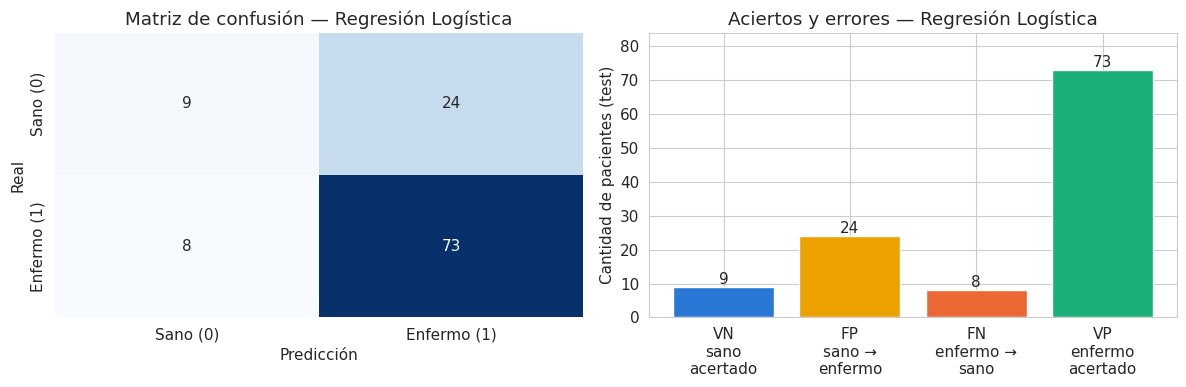

  FN (enfermo NO detectado, el error más grave): 8
  FP (sano enviado a más exámenes): 24

              precision    recall  f1-score   support

    Sano (0)      0.529     0.273     0.360        33
 Enfermo (1)      0.753     0.901     0.820        81

    accuracy                          0.719       114
   macro avg      0.641     0.587     0.590       114
weighted avg      0.688     0.719     0.687       114



In [ ]:
# D.1.2  Evaluación en test
metrics_lr = eval_classifier(pipe_lr, X_train, y_train, X_test, y_test, 'Regresión Logística')

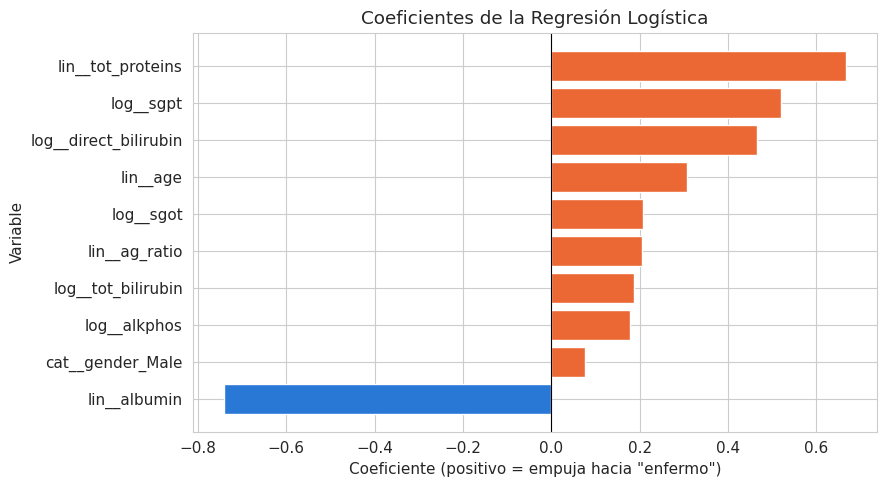

In [ ]:
# D.1.3  Coeficientes (variables estandarizadas): signo y magnitud
coefs = pd.Series(pipe_lr.named_steps['clf'].coef_[0],
                  index=pipe_lr.named_steps['pre'].get_feature_names_out()).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(coefs.index, coefs.values,
        color=[COLOR_SANO if c < 0 else COLOR_ENFERMO for c in coefs])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Coeficientes de la Regresión Logística')
ax.set_xlabel('Coeficiente (positivo = empuja hacia "enfermo")')
ax.set_ylabel('Variable')
plt.tight_layout()
plt.show()

**Lectura de los coeficientes:** la albúmina empuja hacia "sano" y las enzimas y bilirrubinas hacia "enfermo", como se esperaba del EDA. Que `tot_proteins` salga positiva y `albumin` negativa no contradice la clínica: están muy correlacionadas (ρ = 0.78), así que el modelo usa su **diferencia**, que es la globulina (TP − ALB). Por eso los coeficientes de variables correlacionadas **no deben interpretarse por separado**.

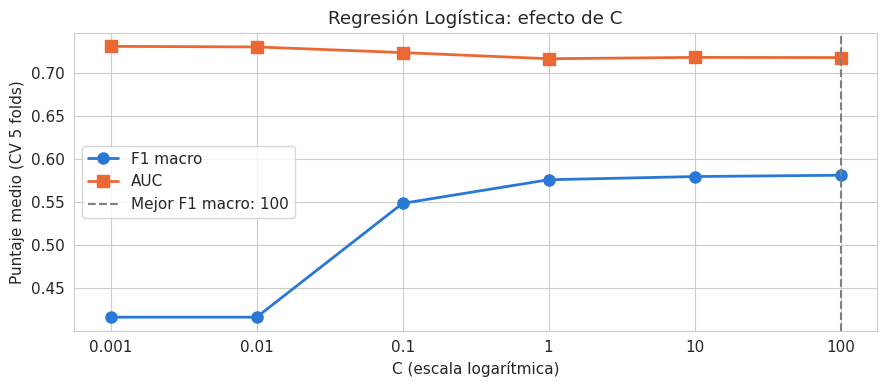

Mejor valor por F1 macro: 100


,C,F1 macro,AUC
0,0.001,0.416,0.731
1,0.010,0.416,0.730
2,0.100,0.548,0.724
3,1.000,0.576,0.716
4,10.000,0.580,0.718
5,100.000,0.581,0.718


In [ ]:
# D.1.4  Exploración del hiperparámetro C (fuerza de regularización)
tabla_C_lr = explorar_hiperparametro(pipe_lr, 'clf__C', [0.001, 0.01, 0.1, 1, 10, 100],
                                     'Regresión Logística: efecto de C', escala_log=True)
tabla_C_lr

---
### D.2 Modelo 2 — Árbol de Decisión

**Fundamento:** CART divide el espacio de variables con preguntas del tipo "¿x ≤ umbral?". En cada nodo elige la variable y el umbral que más reducen la **impureza de Gini**, $G = 1 - \sum_k p_k^2$. Es muy interpretable (se lee como reglas), pero sin límites crece hasta memorizar el train. Se controla con **pre-poda** (`max_depth`, `min_samples_leaf`) o **post-poda** por costo-complejidad (`ccp_alpha`).

In [ ]:
# D.2.1  Árbol SIN restricciones: muestra el sobreajuste
pipe_dt_full = Pipeline([('pre', preprocess_tree),
                         ('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))])
cv_dt_full = resumen_cv(pipe_dt_full, 'Árbol SIN restricciones')
print('\n⚠ Accuracy de train ≈ 1.0 frente a una validación mucho menor = sobreajuste')

Árbol SIN restricciones — validación cruzada (5 folds, train)
  Accuracy train: 1.000 | validación: 0.614 ± 0.026
  f1_macro       : 0.534 ± 0.024
  recall_enfermo : 0.720 ± 0.038
  roc_auc        : 0.535 ± 0.023

⚠ Accuracy de train ≈ 1.0 frente a una validación mucho menor = sobreajuste


In [ ]:
# D.2.2  Árbol con pre-poda (profundidad máxima 4 y al menos 10 pacientes por hoja)
pipe_dt = Pipeline([
    ('pre', preprocess_tree),
    ('clf', DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=RANDOM_STATE)),
])
cv_dt = resumen_cv(pipe_dt, 'Árbol con pre-poda')
pipe_dt.fit(X_train, y_train)
print('✓ Modelo entrenado con todo el train')

Árbol con pre-poda — validación cruzada (5 folds, train)
  Accuracy train: 0.759 | validación: 0.686 ± 0.036
  f1_macro       : 0.535 ± 0.049
  recall_enfermo : 0.874 ± 0.084
  roc_auc        : 0.649 ± 0.043
✓ Modelo entrenado con todo el train


=== Árbol de Decisión ===
  Accuracy en train: 0.743  (para detectar sobreajuste)
  Accuracy            : 0.728
  Precision (enfermo) : 0.745
  Recall (enfermo)    : 0.938
  Recall (sano)       : 0.212
  F1 macro            : 0.571
  AUC                 : 0.772


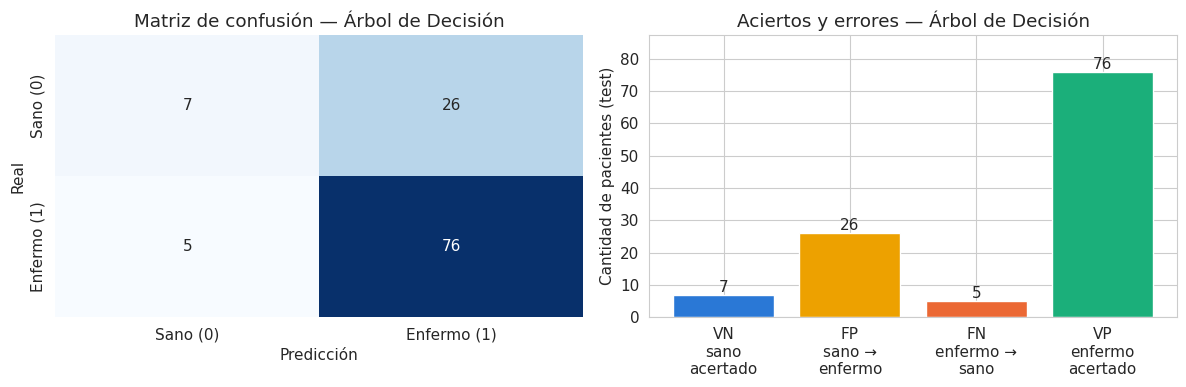

  FN (enfermo NO detectado, el error más grave): 5
  FP (sano enviado a más exámenes): 26

              precision    recall  f1-score   support

    Sano (0)      0.583     0.212     0.311        33
 Enfermo (1)      0.745     0.938     0.831        81

    accuracy                          0.728       114
   macro avg      0.664     0.575     0.571       114
weighted avg      0.698     0.728     0.680       114



In [ ]:
# D.2.3  Evaluación en test
metrics_dt = eval_classifier(pipe_dt, X_train, y_train, X_test, y_test, 'Árbol de Decisión')

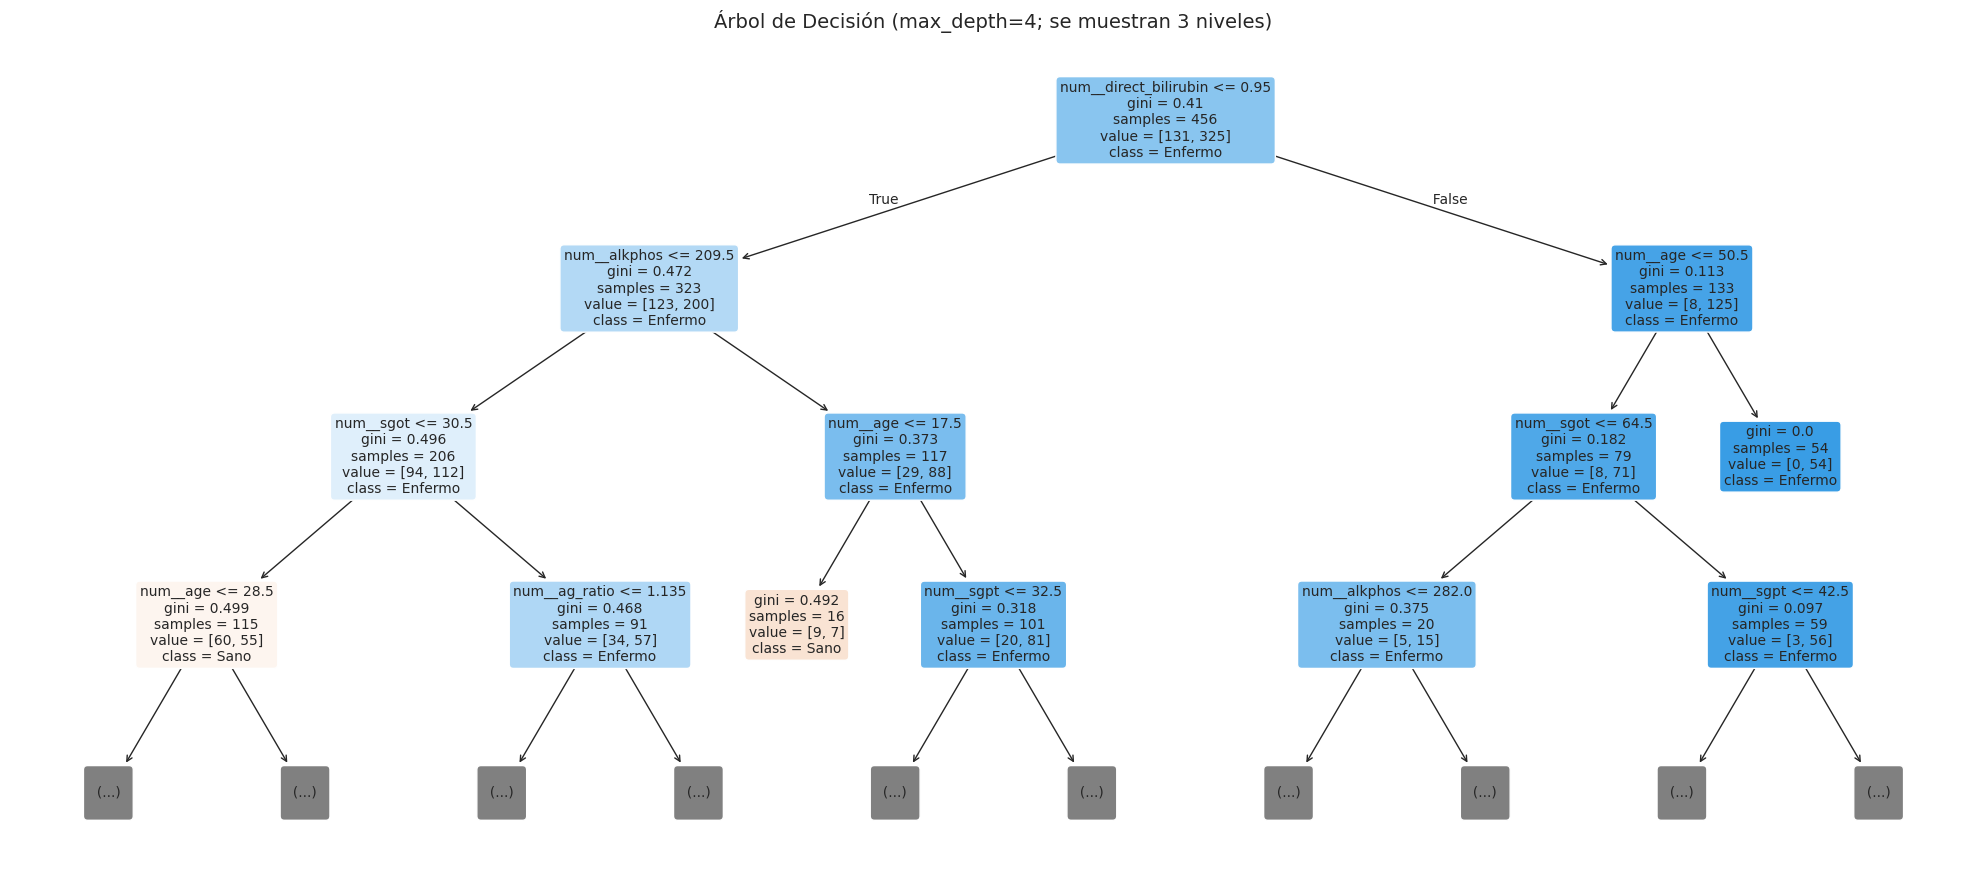

In [ ]:
# D.2.4  Visualización del árbol (primeros 3 niveles para que sea legible)
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(pipe_dt.named_steps['clf'],
          feature_names=list(pipe_dt.named_steps['pre'].get_feature_names_out()),
          class_names=['Sano', 'Enfermo'], filled=True, rounded=True,
          max_depth=3, fontsize=10, ax=ax)
ax.set_title('Árbol de Decisión (max_depth=4; se muestran 3 niveles)', fontsize=14)
plt.tight_layout()
plt.show()

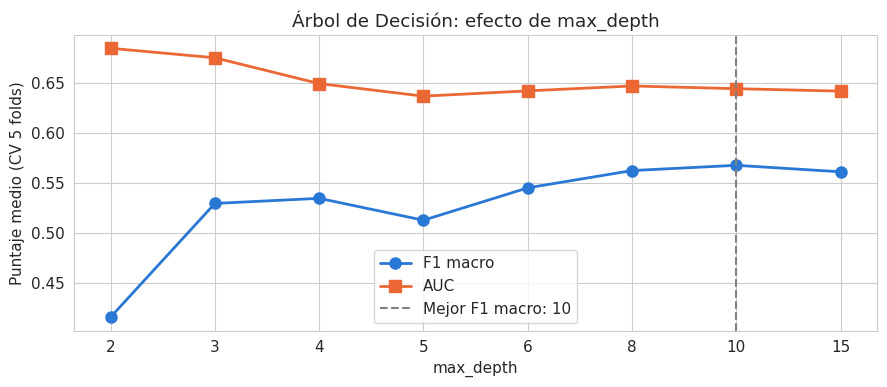

Mejor valor por F1 macro: 10


,max_depth,F1 macro,AUC
0,2,0.416,0.685
1,3,0.530,0.675
2,4,0.535,0.649
3,5,0.513,0.637
4,6,0.545,0.642
5,8,0.562,0.647
6,10,0.568,0.644
7,15,0.561,0.642


In [ ]:
# D.2.5  Exploración de la profundidad máxima
tabla_depth_dt = explorar_hiperparametro(pipe_dt, 'clf__max_depth', [2, 3, 4, 5, 6, 8, 10, 15],
                                         'Árbol de Decisión: efecto de max_depth')
tabla_depth_dt

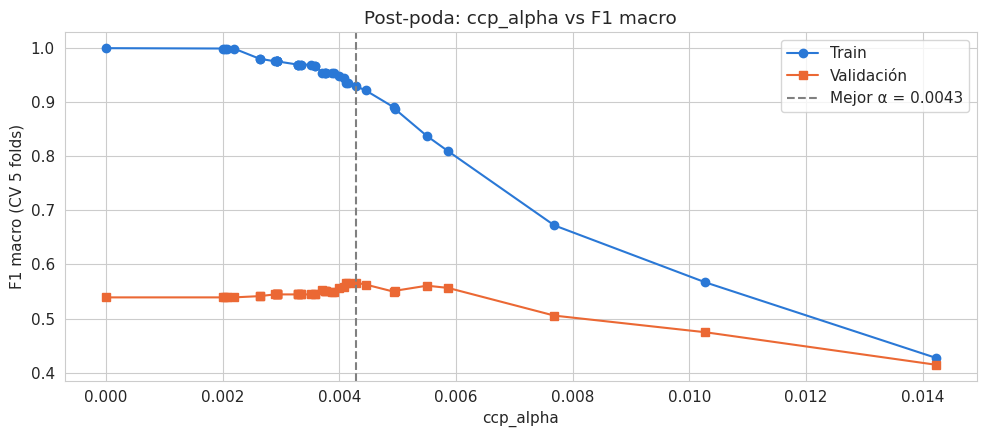

Mejor ccp_alpha: 0.00429  (F1 macro validación = 0.566)


In [ ]:
# D.2.6  Post-poda: ruta de ccp_alpha (se calcula sobre train ya preprocesado)
X_train_tree = preprocess_tree.fit_transform(X_train)
ruta = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(X_train_tree, y_train)
alphas = ruta.ccp_alphas[:-1]          # se excluye el último alpha (árbol de un solo nodo)
alphas = alphas[::max(1, len(alphas) // 25)]   # ~25 valores para que sea rápido

f1_tr, f1_val = [], []
for a in alphas:
    cv_a = cross_validate(DecisionTreeClassifier(ccp_alpha=a, random_state=RANDOM_STATE),
                          X_train_tree, y_train, cv=skf, scoring='f1_macro', return_train_score=True)
    f1_tr.append(cv_a['train_score'].mean())
    f1_val.append(cv_a['test_score'].mean())

mejor_alpha = alphas[int(np.argmax(f1_val))]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(alphas, f1_tr, 'o-', color=COLOR_SANO, label='Train')
ax.plot(alphas, f1_val, 's-', color=COLOR_ENFERMO, label='Validación')
ax.axvline(mejor_alpha, color='gray', linestyle='--', label=f'Mejor α = {mejor_alpha:.4f}')
ax.set_xlabel('ccp_alpha')
ax.set_ylabel('F1 macro (CV 5 folds)')
ax.set_title('Post-poda: ccp_alpha vs F1 macro')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Mejor ccp_alpha: {mejor_alpha:.5f}  (F1 macro validación = {max(f1_val):.3f})')

---
### D.3 Modelo 3 — Random Forest

**Fundamento:** conjunto (*ensemble*) de muchos árboles, cada uno entrenado con una muestra *bootstrap* de los datos y considerando en cada división solo un subconjunto aleatorio de variables. La predicción final es el **voto promedio** de los árboles. Esto reduce la varianza de un árbol individual (menos sobreajuste) a cambio de perder la interpretabilidad de un único árbol; a cambio entrega la **importancia de variables**.

In [ ]:
# D.3.1  Pipeline Random Forest (300 árboles, hojas de al menos 5 pacientes)
pipe_rf = Pipeline([
    ('pre', preprocess_tree),
    ('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                   random_state=RANDOM_STATE, n_jobs=-1)),
])
cv_rf = resumen_cv(pipe_rf, 'Random Forest')
pipe_rf.fit(X_train, y_train)
print('✓ Modelo entrenado con todo el train')

Random Forest — validación cruzada (5 folds, train)
  Accuracy train: 0.913 | validación: 0.702 ± 0.026
  f1_macro       : 0.563 ± 0.049
  recall_enfermo : 0.886 ± 0.023
  roc_auc        : 0.719 ± 0.040
✓ Modelo entrenado con todo el train


=== Random Forest ===
  Accuracy en train: 0.919  (para detectar sobreajuste)
  Accuracy            : 0.737
  Precision (enfermo) : 0.752
  Recall (enfermo)    : 0.938
  Recall (sano)       : 0.242
  F1 macro            : 0.591
  AUC                 : 0.774


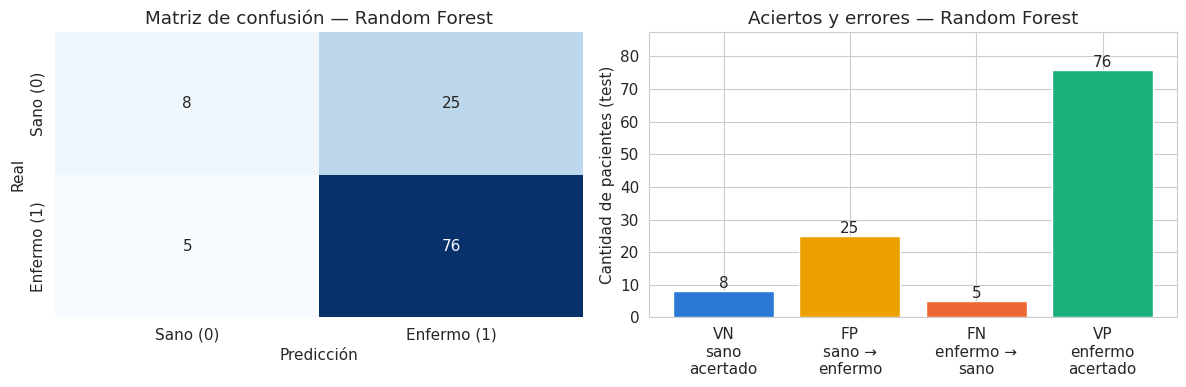

  FN (enfermo NO detectado, el error más grave): 5
  FP (sano enviado a más exámenes): 25

              precision    recall  f1-score   support

    Sano (0)      0.615     0.242     0.348        33
 Enfermo (1)      0.752     0.938     0.835        81

    accuracy                          0.737       114
   macro avg      0.684     0.590     0.591       114
weighted avg      0.713     0.737     0.694       114



In [ ]:
# D.3.2  Evaluación en test
metrics_rf = eval_classifier(pipe_rf, X_train, y_train, X_test, y_test, 'Random Forest')

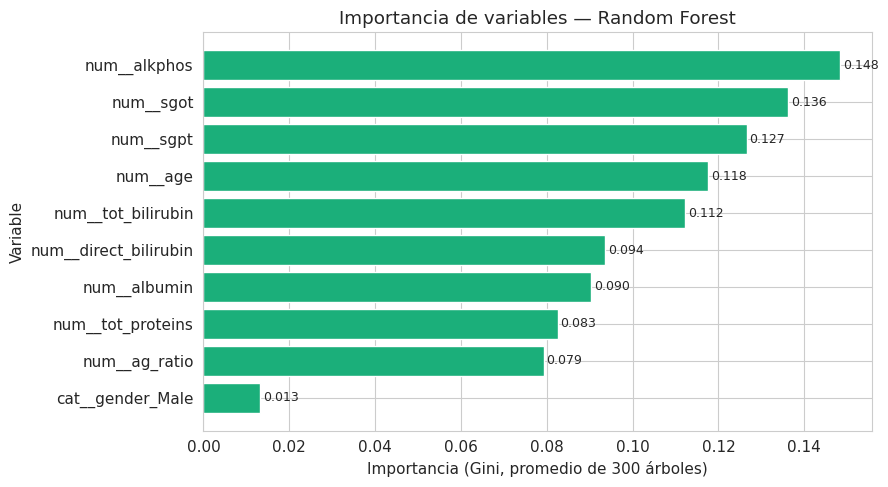

In [ ]:
# D.3.3  Importancia de variables (disminución media de impureza)
imp = pd.Series(pipe_rf.named_steps['clf'].feature_importances_,
                index=pipe_rf.named_steps['pre'].get_feature_names_out()).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(imp.index, imp.values, color='#1baf7a')
ax.bar_label(barras, fmt='%.3f', fontsize=9, padding=2)
ax.set_title('Importancia de variables — Random Forest')
ax.set_xlabel('Importancia (Gini, promedio de 300 árboles)')
ax.set_ylabel('Variable')
plt.tight_layout()
plt.show()

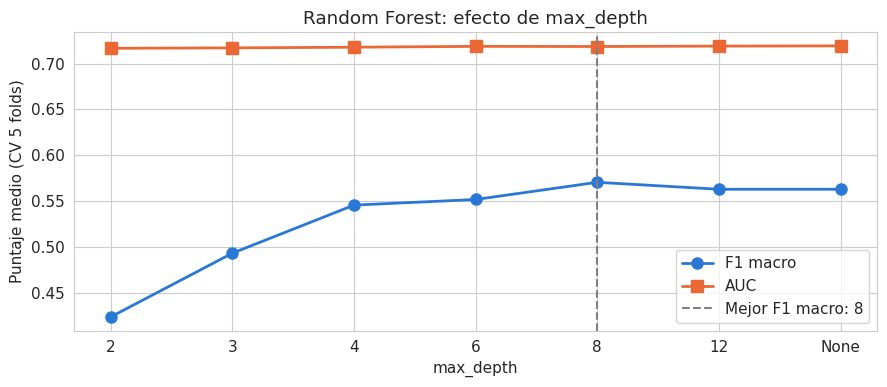

Mejor valor por F1 macro: 8


,max_depth,F1 macro,AUC
0,2.0,0.423,0.717
1,3.0,0.493,0.717
2,4.0,0.545,0.718
3,6.0,0.552,0.719
4,8.0,0.570,0.719
5,12.0,0.563,0.719
6,NaN,0.563,0.719


In [ ]:
# D.3.4  Exploración de la profundidad máxima de los árboles del bosque
tabla_depth_rf = explorar_hiperparametro(pipe_rf, 'clf__max_depth', [2, 3, 4, 6, 8, 12, None],
                                         'Random Forest: efecto de max_depth')
tabla_depth_rf

---
### D.4 Modelo 4 — Support Vector Machine (SVM)

**Fundamento:** busca el hiperplano que separa las clases con el **máximo margen** $\gamma = 2/\lVert w\rVert$. Con margen suave resuelve $\min \tfrac12\lVert w\rVert^2 + C\sum \xi_i$: **C** controla cuántos errores se toleran (C alto = margen estrecho y riesgo de sobreajuste). El **kernel** (lineal, RBF, polinómico) permite fronteras no lineales sin construir explícitamente nuevas variables (*kernel trick*). Como trabaja con distancias, **exige escalado**. `probability=True` habilita `predict_proba` (necesario para la ROC).

In [ ]:
# D.4.1  Pipeline SVM con kernel RBF y C = 1 (valores por defecto)
pipe_svm = Pipeline([
    ('pre', preprocess_scaled),
    ('clf', SVC(kernel='rbf', C=1.0, probability=True, random_state=RANDOM_STATE)),
])
cv_svm = resumen_cv(pipe_svm, 'SVM (RBF)')
pipe_svm.fit(X_train, y_train)
print('✓ Modelo entrenado con todo el train')

SVM (RBF) — validación cruzada (5 folds, train)
  Accuracy train: 0.738 | validación: 0.706 ± 0.019
  f1_macro       : 0.444 ± 0.026
  recall_enfermo : 0.975 ± 0.042
  roc_auc        : 0.629 ± 0.049
✓ Modelo entrenado con todo el train


=== SVM (RBF) ===
  Accuracy en train: 0.724  (para detectar sobreajuste)
  Accuracy            : 0.711
  Precision (enfermo) : 0.711
  Recall (enfermo)    : 1.000
  Recall (sano)       : 0.000
  F1 macro            : 0.415
  AUC                 : 0.666


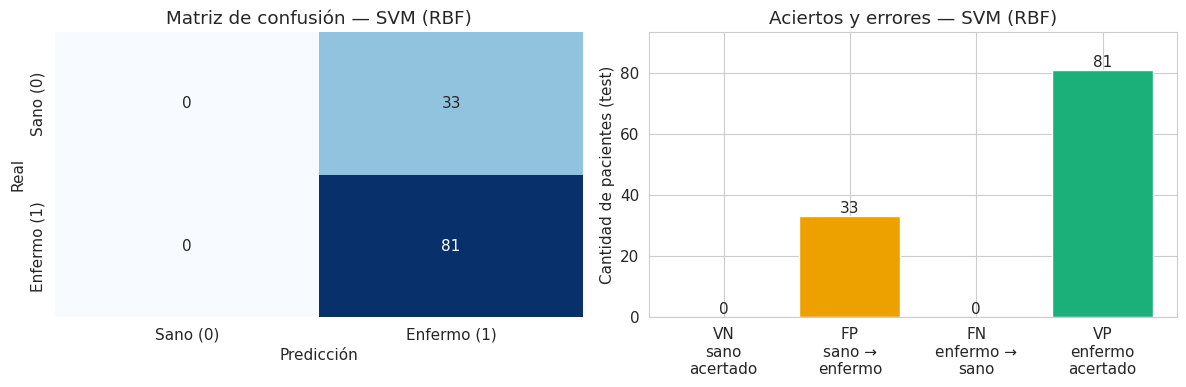

  FN (enfermo NO detectado, el error más grave): 0
  FP (sano enviado a más exámenes): 33

              precision    recall  f1-score   support

    Sano (0)      0.000     0.000     0.000        33
 Enfermo (1)      0.711     1.000     0.831        81

    accuracy                          0.711       114
   macro avg      0.355     0.500     0.415       114
weighted avg      0.505     0.711     0.590       114



In [ ]:
# D.4.2  Evaluación en test
metrics_svm = eval_classifier(pipe_svm, X_train, y_train, X_test, y_test, 'SVM (RBF)')

**Lectura del SVM:** con C = 1 y sin balanceo, el SVM predice **"enfermo" para los 114 pacientes del test**: recall de enfermo 1.00 y recall de sano 0.00, exactamente igual que la línea base. Su accuracy (0.711) parece aceptable solo porque coincide con la proporción de enfermos. Es el ejemplo más claro de por qué en este problema no basta con mirar accuracy ni el recall de enfermo: hay que revisar el F1 macro y la matriz de confusión. Las exploraciones siguientes muestran que mejora con un margen menos suave (C alto).

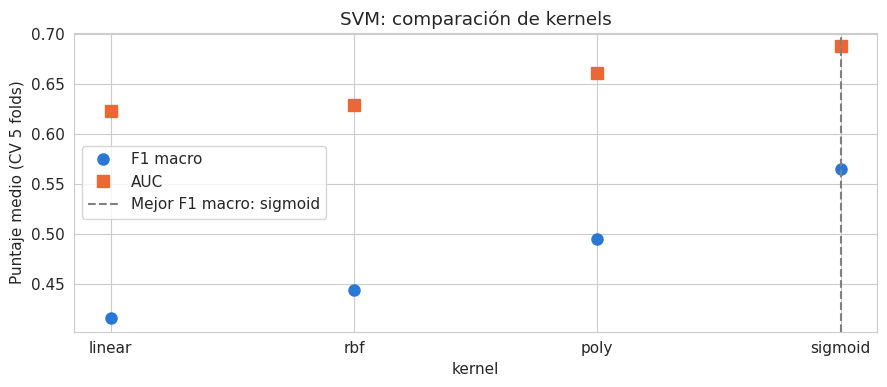

Mejor valor por F1 macro: sigmoid


,kernel,F1 macro,AUC
0,linear,0.416,0.623
1,rbf,0.444,0.629
2,poly,0.495,0.661
3,sigmoid,0.565,0.688


In [ ]:
# D.4.3  Exploración del kernel
tabla_kernel = explorar_hiperparametro(pipe_svm, 'clf__kernel', ['linear', 'rbf', 'poly', 'sigmoid'],
                                       'SVM: comparación de kernels')
tabla_kernel

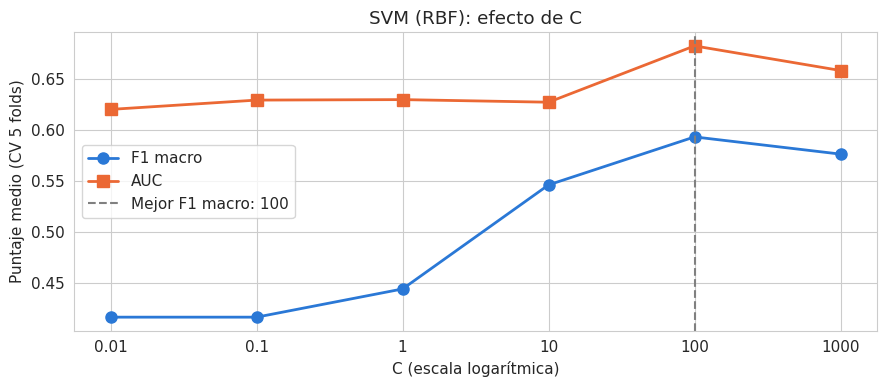

Mejor valor por F1 macro: 100


,C,F1 macro,AUC
0,0.01,0.416,0.620
1,0.10,0.416,0.629
2,1.00,0.444,0.629
3,10.00,0.546,0.627
4,100.00,0.593,0.682
5,1000.00,0.576,0.658


In [ ]:
# D.4.4  Exploración de C (kernel RBF)
tabla_C_svm = explorar_hiperparametro(pipe_svm, 'clf__C', [0.01, 0.1, 1, 10, 100, 1000],
                                      'SVM (RBF): efecto de C', escala_log=True)
tabla_C_svm

---
### D.5 Modelo 5 — K-Nearest Neighbors (KNN)

**Fundamento:** aprendizaje basado en instancias (*lazy learning*): no construye un modelo, guarda el train y clasifica a un paciente nuevo por **voto de sus K vecinos más cercanos** (distancia euclidiana por defecto). K pequeño = frontera muy irregular (sobreajuste); K grande = frontera suave (subajuste). Como se basa en distancias, **exige escalado**; si no, AST (miles de U/L) dominaría a la albúmina (unidades de g/dL).

In [ ]:
# D.5.1  Pipeline KNN con K = 5
pipe_knn = Pipeline([
    ('pre', preprocess_scaled),
    ('clf', KNeighborsClassifier(n_neighbors=5)),
])
cv_knn = resumen_cv(pipe_knn, 'KNN (K=5)')
pipe_knn.fit(X_train, y_train)
print('✓ Modelo entrenado con todo el train')

KNN (K=5) — validación cruzada (5 folds, train)
  Accuracy train: 0.805 | validación: 0.695 ± 0.022
  f1_macro       : 0.598 ± 0.023
  recall_enfermo : 0.831 ± 0.039
  roc_auc        : 0.700 ± 0.041
✓ Modelo entrenado con todo el train


=== KNN (K=5) ===
  Accuracy en train: 0.829  (para detectar sobreajuste)
  Accuracy            : 0.737
  Precision (enfermo) : 0.763
  Recall (enfermo)    : 0.914
  Recall (sano)       : 0.303
  F1 macro            : 0.616
  AUC                 : 0.744


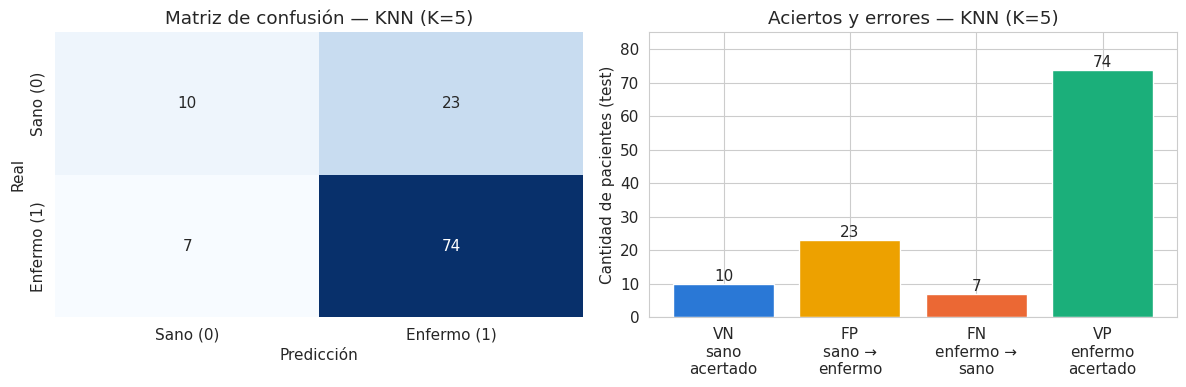

  FN (enfermo NO detectado, el error más grave): 7
  FP (sano enviado a más exámenes): 23

              precision    recall  f1-score   support

    Sano (0)      0.588     0.303     0.400        33
 Enfermo (1)      0.763     0.914     0.831        81

    accuracy                          0.737       114
   macro avg      0.676     0.608     0.616       114
weighted avg      0.712     0.737     0.707       114



In [ ]:
# D.5.2  Evaluación en test
metrics_knn = eval_classifier(pipe_knn, X_train, y_train, X_test, y_test, 'KNN (K=5)')

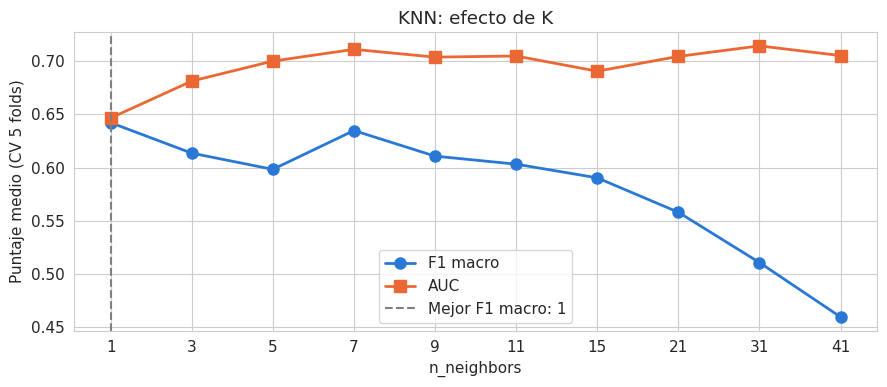

Mejor valor por F1 macro: 1
Regla empírica K ≈ √n = √456 ≈ 21


,n_neighbors,F1 macro,AUC
0,1,0.642,0.647
1,3,0.614,0.681
2,5,0.598,0.700
3,7,0.635,0.711
4,9,0.611,0.704
5,11,0.603,0.705
6,15,0.590,0.691
7,21,0.558,0.705
8,31,0.511,0.714
9,41,0.460,0.705


In [ ]:
# D.5.3  Búsqueda del K óptimo
valores_k = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41]
tabla_k = explorar_hiperparametro(pipe_knn, 'clf__n_neighbors', valores_k, 'KNN: efecto de K')
print(f'Regla empírica K ≈ √n = √{len(X_train)} ≈ {int(np.sqrt(len(X_train)))}')
tabla_k

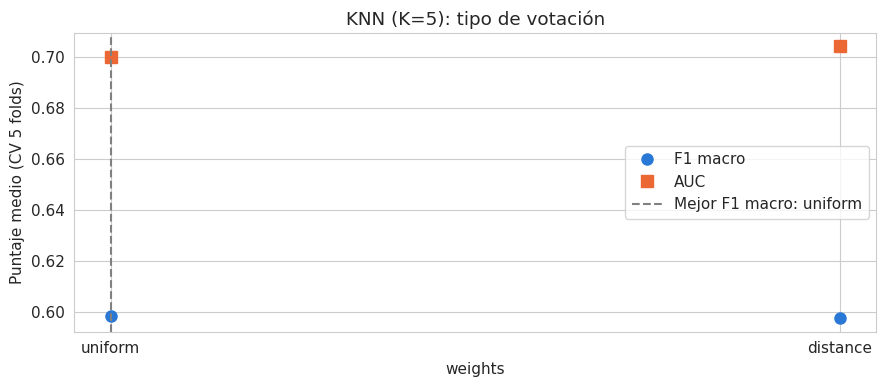

Mejor valor por F1 macro: uniform


,weights,F1 macro,AUC
0,uniform,0.598,0.700
1,distance,0.598,0.704


In [ ]:
# D.5.4  Votación uniforme vs ponderada por distancia
tabla_pesos = explorar_hiperparametro(pipe_knn, 'clf__weights', ['uniform', 'distance'],
                                      'KNN (K=5): tipo de votación')
tabla_pesos

---
### D.6 Resumen de la exploración de hiperparámetros

| Modelo | Hiperparámetro explorado | Mejor valor (F1 macro, CV) | Lectura |
|---|---|---|---|
| Regresión Logística | `C` | 100 (F1 = 0.581) | Con C ≤ 0.01 la regularización es tan fuerte que predice todo "enfermo" (F1 = 0.416). Desde C = 1 el F1 se estabiliza; el AUC casi no cambia (≈ 0.72). |
| Árbol de Decisión | `max_depth`, `ccp_alpha` | profundidad 10 (F1 = 0.568); α = 0.0043 | Sin poda: train 1.00 vs validación 0.61 (sobreajuste). F1 y AUC no coinciden: el mejor AUC está en profundidad 2–3. |
| Random Forest | `max_depth` | 8 (F1 = 0.570) | El AUC es estable (≈ 0.72) en cualquier profundidad ≥ 2; promediar 300 árboles reduce la varianza del árbol individual. |
| SVM | `kernel`, `C` | sigmoid (0.565); C = 100 (0.593) | Con C bajo el SVM colapsa a la clase mayoritaria; necesita C alto o balanceo para reconocer a los sanos. |
| KNN | `n_neighbors`, `weights` | K = 1 (F1 = 0.642); uniform ≈ distance | K = 1 maximiza el F1 pero tiene el **peor AUC** (0.647); K = 7 (F1 = 0.635, AUC = 0.711) es mejor compromiso. Con K grande vuelve a predecir todo "enfermo". |

**Conclusión:** en todos los modelos, la configuración por defecto favorece a la clase mayoritaria. Los hiperparámetros que dan más flexibilidad (C alto, más profundidad, K pequeño) mejoran el F1 macro porque permiten reconocer a algunos sanos, pero el AUC (capacidad de ordenar) apenas cambia y se mantiene entre 0.65 y 0.73. Esto sugiere que el límite del desempeño viene de los datos y no del ajuste fino.

---
## E. Evaluación comparativa

In [ ]:
# E.1  Tabla resumen: métricas en test + AUC de validación cruzada (más estable)
modelos = {
    'Regresión Logística': pipe_lr,
    'Árbol de Decisión':   pipe_dt,
    'Random Forest':       pipe_rf,
    'SVM (RBF)':           pipe_svm,
    'KNN (K=5)':           pipe_knn,
}
cvs = {'Regresión Logística': cv_lr, 'Árbol de Decisión': cv_dt, 'Random Forest': cv_rf,
       'SVM (RBF)': cv_svm, 'KNN (K=5)': cv_knn}
metricas_test = {'Regresión Logística': metrics_lr, 'Árbol de Decisión': metrics_dt,
                 'Random Forest': metrics_rf, 'SVM (RBF)': metrics_svm, 'KNN (K=5)': metrics_knn}

tabla = pd.DataFrame(metricas_test).T
tabla['AUC (CV)'] = [cvs[m]['test_roc_auc'].mean() for m in tabla.index]
tabla['F1 macro (CV)'] = [cvs[m]['test_f1_macro'].mean() for m in tabla.index]
tabla.loc['Línea base (siempre "enfermo")'] = [
    accuracy_score(y_test, y_dummy), precision_score(y_test, y_dummy),
    recall_score(y_test, y_dummy), recall_score(y_test, y_dummy, pos_label=0),
    f1_score(y_test, y_dummy, average='macro'), 0.5, 0.5, np.nan]
tabla = tabla[['Accuracy', 'F1 macro', 'AUC', 'Recall (enfermo)', 'Recall (sano)',
               'Precision (enfermo)', 'F1 macro (CV)', 'AUC (CV)']].round(3)
print('=== Métricas en TEST (y en validación cruzada sobre train) ===')
tabla

=== Métricas en TEST (y en validación cruzada sobre train) ===


,Accuracy,F1 macro,AUC,Recall (enfermo),Recall (sano),Precision (enfermo),F1 macro (CV),AUC (CV)
Regresión Logística,0.719,0.590,0.813,0.901,0.273,0.753,0.576,0.716
Árbol de Decisión,0.728,0.571,0.772,0.938,0.212,0.745,0.535,0.649
Random Forest,0.737,0.591,0.774,0.938,0.242,0.752,0.563,0.719
SVM (RBF),0.711,0.415,0.666,1.000,0.000,0.711,0.444,0.629
KNN (K=5),0.737,0.616,0.744,0.914,0.303,0.763,0.598,0.700
"Línea base (siempre ""enfermo"")",0.711,0.415,0.500,1.000,0.000,0.711,NaN,0.500


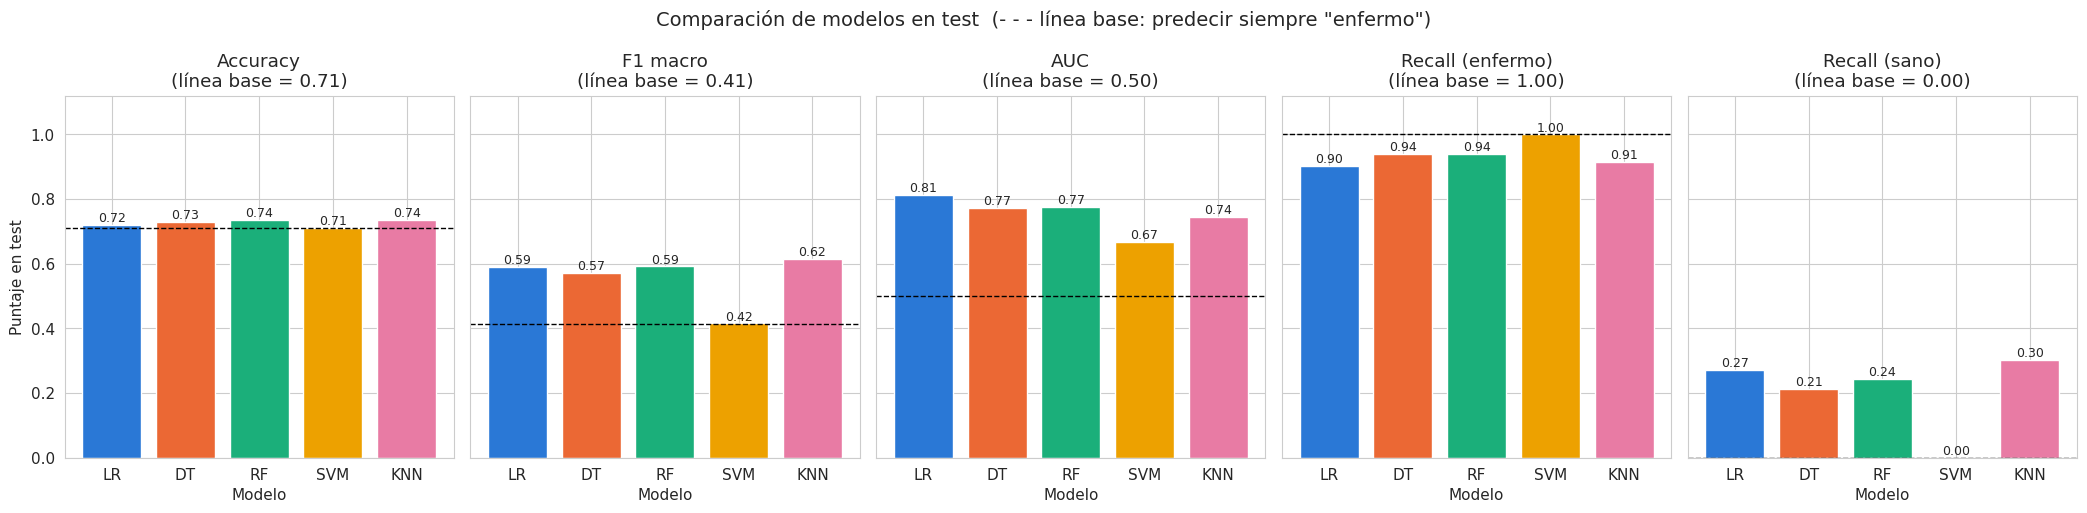

In [ ]:
# E.2  Gráfico de barras comparativo (una gráfica por métrica)
METRICAS_GRAF = ['Accuracy', 'F1 macro', 'AUC', 'Recall (enfermo)', 'Recall (sano)']
abrev = ['LR', 'DT', 'RF', 'SVM', 'KNN']
linea_base = tabla.loc['Línea base (siempre "enfermo")']

fig, axes = plt.subplots(1, 5, figsize=(21, 5.2), sharey=True)
for ax, met in zip(axes, METRICAS_GRAF):
    valores = [metricas_test[m][met] for m in modelos]
    barras = ax.bar(abrev, valores, color=COLORES_MODELOS)
    ax.bar_label(barras, fmt='%.2f', fontsize=9)
    ax.axhline(linea_base[met], color='black', linestyle='--', linewidth=1)  # línea base
    ax.set_title(f'{met}\n(línea base = {linea_base[met]:.2f})')
    ax.set_ylim(0, 1.12)
    ax.set_xlabel('Modelo')
axes[0].set_ylabel('Puntaje en test')
plt.suptitle('Comparación de modelos en test  (- - - línea base: predecir siempre "enfermo")', fontsize=14)
plt.tight_layout()
plt.show()

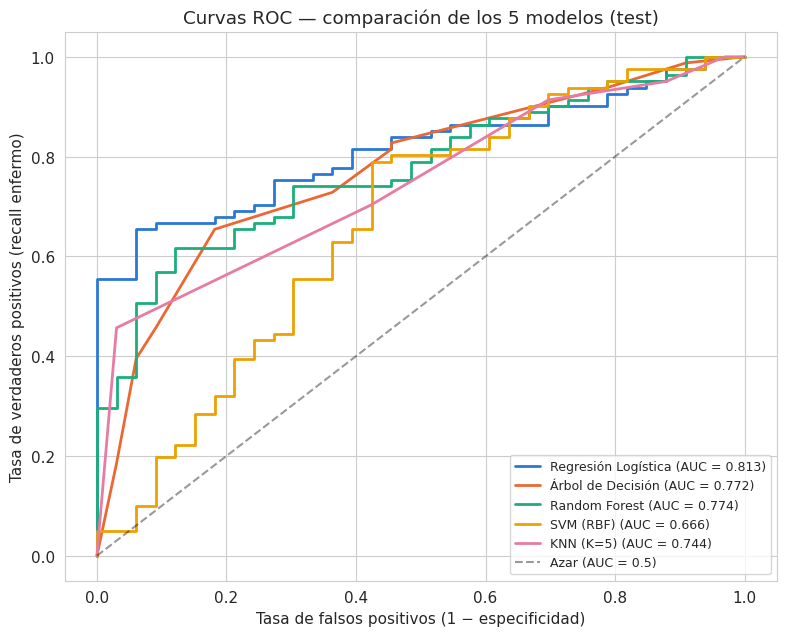

In [ ]:
# E.3  Curvas ROC superpuestas
fig, ax = plt.subplots(figsize=(8, 6.5))
for (nombre, modelo), color in zip(modelos.items(), COLORES_MODELOS):
    plot_roc(modelo, X_test, y_test, nombre, ax=ax, color=color)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Azar (AUC = 0.5)')
ax.set_title('Curvas ROC — comparación de los 5 modelos (test)')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

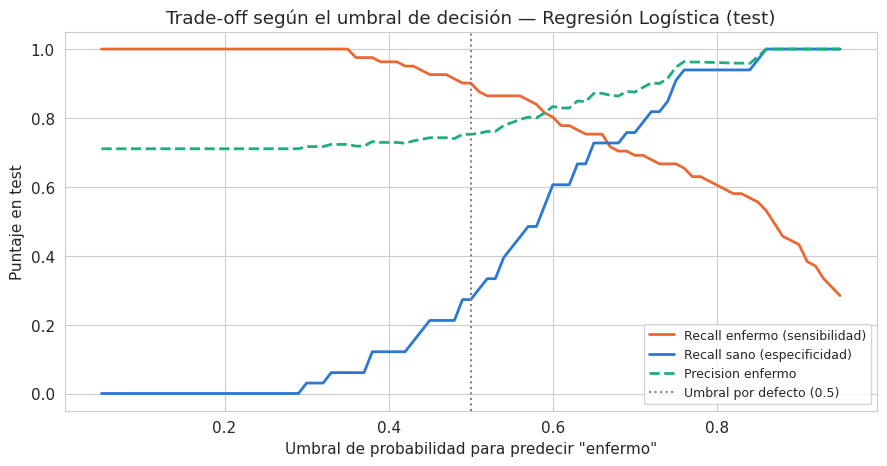

In [ ]:
# E.4  Trade-off según el umbral de decisión — Regresión Logística
# (empatada con RF en AUC de CV y con el mejor AUC en test; es la candidata de la Sección F)
candidato = 'Regresión Logística'
proba = modelos[candidato].predict_proba(X_test)[:, 1]
umbrales = np.linspace(0.05, 0.95, 91)
rec_enf = [recall_score(y_test, proba >= u) for u in umbrales]
rec_sano = [recall_score(y_test, proba >= u, pos_label=0) for u in umbrales]
prec_enf = [precision_score(y_test, proba >= u, zero_division=1) for u in umbrales]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(umbrales, rec_enf, color=COLOR_ENFERMO, linewidth=2, label='Recall enfermo (sensibilidad)')
ax.plot(umbrales, rec_sano, color=COLOR_SANO, linewidth=2, label='Recall sano (especificidad)')
ax.plot(umbrales, prec_enf, color='#1baf7a', linewidth=2, linestyle='--', label='Precision enfermo')
ax.axvline(0.5, color='gray', linestyle=':', label='Umbral por defecto (0.5)')
ax.set_title(f'Trade-off según el umbral de decisión — {candidato} (test)')
ax.set_xlabel('Umbral de probabilidad para predecir "enfermo"')
ax.set_ylabel('Puntaje en test')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
# E.5  Matriz de selección de modelos
# Las dos primeras columnas salen de los resultados (estrellas según el ranking);
# las demás son propiedades conocidas de cada algoritmo.
def estrellas(serie):
    '''Convierte valores en 1–5 estrellas según su posición entre el mínimo y el máximo.'''
    n = 1 + np.round(4 * (serie - serie.min()) / (serie.max() - serie.min())).astype(int)
    return n.map(lambda k: '★' * k + '☆' * (5 - k))

t = tabla.drop('Línea base (siempre "enfermo")')
matriz_seleccion = pd.DataFrame({
    'Discriminación (AUC CV)':  estrellas(t['AUC (CV)']),
    'Equilibrio (F1 macro CV)': estrellas(t['F1 macro (CV)']),
    'Interpretabilidad':  ['★★★★☆', '★★★★★', '★★☆☆☆', '★☆☆☆☆', '★★★☆☆'],
    'Velocidad':          ['★★★★★', '★★★★★', '★★★☆☆', '★★★☆☆', '★★★★☆'],
    'Robustez a outliers': ['★★★☆☆', '★★★★★', '★★★★★', '★★★☆☆', '★★☆☆☆'],
}, index=t.index)
print('=== Matriz de selección de modelos ===')
matriz_seleccion

=== Matriz de selección de modelos ===


,Discriminación (AUC CV),Equilibrio (F1 macro CV),Interpretabilidad,Velocidad,Robustez a outliers
Regresión Logística,★★★★★,★★★★☆,★★★★☆,★★★★★,★★★☆☆
Árbol de Decisión,★★☆☆☆,★★★☆☆,★★★★★,★★★★★,★★★★★
Random Forest,★★★★★,★★★★☆,★★☆☆☆,★★★☆☆,★★★★★
SVM (RBF),★☆☆☆☆,★☆☆☆☆,★☆☆☆☆,★★★☆☆,★★★☆☆
KNN (K=5),★★★★☆,★★★★★,★★★☆☆,★★★★☆,★★☆☆☆


### Resumen comparativo

| Modelo | Fortalezas | Limitaciones | ¿Cuándo usarlo? |
|---|---|---|---|
| **Regresión Logística** | Interpretable (coeficientes con signo), entrega probabilidades calibradas, rápida, estable con pocos datos | Frontera lineal; sensible a variables correlacionadas (bilirrubinas, ALT/AST) | Cuando se necesita explicar la decisión al personal de salud y los datos son pocos |
| **Árbol de Decisión** | Reglas legibles ("si bilirrubina > x…"), no necesita escalado, captura interacciones | Inestable y propenso a sobreajuste sin poda | Para protocolos simples de derivación o para explicar el problema |
| **Random Forest** | Robusto a outliers, captura no linealidad, da importancia de variables | Menos interpretable, más lento, puede sobreajustar con pocos datos | Cuando prima el desempeño y hay más datos |
| **SVM** | Fronteras no lineales con kernel, buen AUC con datos escalados | Sin balanceo tiende a predecir solo la clase mayoritaria; difícil de interpretar; sensible a C | Datasets medianos, bien escalados, con balanceo de clases |
| **KNN** | Simple, sin entrenamiento, se adapta a fronteras irregulares | Sensible a la escala y a variables irrelevantes; lento al predecir con muchos datos | Línea de comparación o datasets pequeños y bien escalados |

### Análisis de trade-offs
**Accuracy engaña:** todos los modelos base (0.71–0.74) apenas superan a la línea base que dice siempre "enfermo" (0.711); la diferencia real aparece en el F1 macro y el AUC. **Precision vs recall:** sin balanceo, todos tienen recall de enfermo alto (0.90–1.00) pero reconocen a muy pocos sanos (recall de sano 0.00–0.30), así que casi todos los sanos terminan como falsos positivos; el SVM por defecto es el caso extremo. **Costo de los errores:** un falso negativo (enfermo no detectado) retrasa un diagnóstico, mientras que un falso positivo cuesta más exámenes. Conviene un recall de enfermo alto, pero no al extremo de "todos enfermos", que no aporta información. **Discriminación:** por AUC en CV, Regresión Logística (0.716) y Random Forest (0.719) empatan dentro de su desviación (± 0.03–0.04). En test la LR logra el mejor AUC (0.813), pero el test es pequeño (114 pacientes, 33 sanos), así que la CV es más confiable. **Sobreajuste:** el árbol sin poda (train 1.00 / validación 0.61) y el RF (0.91 / 0.70) memorizan; la LR casi no tiene brecha (0.74 / 0.72). **Interpretabilidad y costo:** la LR y el árbol se pueden explicar al personal de salud; el RF y el SVM no. La LR es además la más rápida.

**Decisión:** se elige la **Regresión Logística** para optimizar en la Sección F. Está en el grupo líder de AUC en CV, tiene el mejor AUC en test, el menor sobreajuste y es interpretable. KNN tiene el mejor F1 macro base, pero su AUC es menor y su desempeño depende mucho de K.

---
## F. Modelo final y serialización

**Modelo elegido:** Regresión Logística (justificación al final de la Sección E).

**Búsqueda de hiperparámetros:** `GridSearchCV` con `StratifiedKFold(5)` sobre **2 hiperparámetros**:
- `C` ∈ {0.001 … 100}: inverso de la fuerza de regularización.
- `penalty` ∈ {`l1`, `l2`}: L1 puede llevar coeficientes exactamente a 0 (selecciona variables, útil con las variables redundantes del EDA); L2 los encoge sin anularlos. Se usa `solver='saga'`, que admite ambas.

**Criterio de selección (`refit`)**: **F1 macro**. El recall de enfermo por sí solo no sirve como criterio porque se maximiza de forma trivial prediciendo "enfermo" a todos (lo demostraron la línea base y el SVM). También se registran el AUC y el recall de enfermo.

**Desbalance:** la misma grilla se repite con tres estrategias: **sin balancear**, **`class_weight='balanced'`** (pesa más los errores en la clase minoritaria) y **SMOTE** (crea sanos sintéticos interpolando vecinos, solo dentro de los folds de entrenamiento).

In [ ]:
# F.1  GridSearchCV con StratifiedKFold sobre el modelo elegido
NOMBRE_FINAL = 'Regresión Logística'
pipe_base = Pipeline([
    ('pre', preprocess_scaled),
    ('clf', LogisticRegression(solver='saga', max_iter=5000, random_state=RANDOM_STATE)),
])
param_grid = {
    'clf__C': [0.001, 0.01, 0.1, 0.3, 1, 3, 10, 100],
    'clf__penalty': ['l1', 'l2'],
}

def buscar(pipe, etiqueta):
    """GridSearchCV (StratifiedKFold 5) que elige por F1 macro y reporta las demás métricas."""
    grid = GridSearchCV(pipe, param_grid, cv=skf, scoring=SCORING, refit='f1_macro', n_jobs=-1)
    grid.fit(X_train, y_train)
    r, i = grid.cv_results_, grid.best_index_
    print(f'{etiqueta:25s} -> {grid.best_params_}')
    print(f"{'':25s}    F1 macro CV = {r['mean_test_f1_macro'][i]:.3f} | AUC CV = {r['mean_test_roc_auc'][i]:.3f}"
          f" | Recall enfermo CV = {r['mean_test_recall_enfermo'][i]:.3f}")
    return grid

print(f'Grilla: {len(param_grid["clf__C"]) * len(param_grid["clf__penalty"])} combinaciones × 5 folds por estrategia')

Grilla: 16 combinaciones × 5 folds por estrategia


In [ ]:
# F.2  Las tres estrategias frente al desbalance, con la MISMA grilla
grid_sin = buscar(pipe_base, 'Sin balancear')

pipe_cw = clone(pipe_base).set_params(clf__class_weight='balanced')
grid_cw = buscar(pipe_cw, "class_weight='balanced'")

# SMOTE va DENTRO del pipeline de imblearn: así solo se generan pacientes sintéticos
# a partir de los folds de entrenamiento y nunca a partir de la validación o el test.
pipe_smote = ImbPipeline([
    ('pre', clone(pipe_base.named_steps['pre'])),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('clf', clone(pipe_base.named_steps['clf'])),
])
grid_smote = buscar(pipe_smote, 'SMOTE')

Sin balancear             -> {'clf__C': 100, 'clf__penalty': 'l1'}
                             F1 macro CV = 0.581 | AUC CV = 0.718 | Recall enfermo CV = 0.905
class_weight='balanced'   -> {'clf__C': 0.3, 'clf__penalty': 'l2'}
                             F1 macro CV = 0.625 | AUC CV = 0.720 | Recall enfermo CV = 0.591
SMOTE                     -> {'clf__C': 10, 'clf__penalty': 'l2'}
                             F1 macro CV = 0.620 | AUC CV = 0.714 | Recall enfermo CV = 0.609


In [ ]:
# F.3  Comparación en test: sin balancear vs class_weight vs SMOTE
grids = {'Sin balancear': grid_sin, "class_weight='balanced'": grid_cw, 'SMOTE': grid_smote}
filas = []
for nombre, g in grids.items():
    y_pred = g.predict(X_test)
    filas.append({
        'Estrategia': nombre,
        'Mejores hiperparámetros': {k.replace('clf__', ''): v for k, v in g.best_params_.items()},
        'F1 macro (CV)': g.best_score_,
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1 macro': f1_score(y_test, y_pred, average='macro'),
        'AUC': roc_auc_score(y_test, g.predict_proba(X_test)[:, 1]),
        'Recall (enfermo)': recall_score(y_test, y_pred),
        'Recall (sano)': recall_score(y_test, y_pred, pos_label=0),
    })
comparacion_balanceo = pd.DataFrame(filas).set_index('Estrategia').round(3)
comparacion_balanceo

,Mejores hiperparámetros,F1 macro (CV),Accuracy,F1 macro,AUC,Recall (enfermo),Recall (sano)
Estrategia,,,,,,,
Sin balancear,"{'C': 100, 'penalty': 'l1'}",0.581,0.719,0.601,0.807,0.889,0.303
class_weight='balanced',"{'C': 0.3, 'penalty': 'l2'}",0.625,0.728,0.706,0.813,0.704,0.788
SMOTE,"{'C': 10, 'penalty': 'l2'}",0.620,0.702,0.680,0.819,0.679,0.758


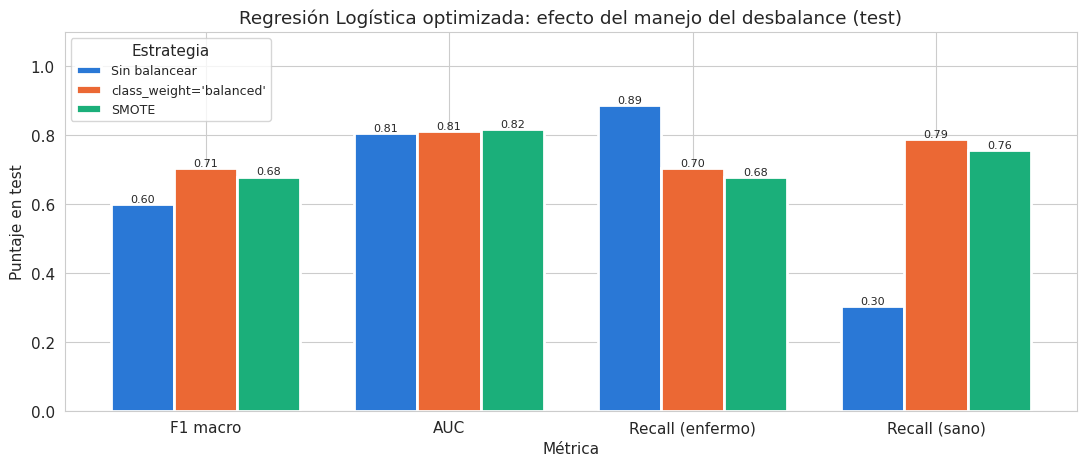

In [ ]:
# F.4  Gráfico de la comparación de estrategias de balanceo
mets = ['F1 macro', 'AUC', 'Recall (enfermo)', 'Recall (sano)']
x = np.arange(len(mets))
ancho = 0.26
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, (estrategia, color) in enumerate(zip(comparacion_balanceo.index, COLORES_MODELOS)):
    barras = ax.bar(x + (i - 1) * ancho, comparacion_balanceo.loc[estrategia, mets], ancho,
                    color=color, label=estrategia, edgecolor='white', linewidth=2)
    ax.bar_label(barras, fmt='%.2f', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(mets)
ax.set_ylim(0, 1.1)
ax.set_xlabel('Métrica')
ax.set_ylabel('Puntaje en test')
ax.set_title(f'{NOMBRE_FINAL} optimizada: efecto del manejo del desbalance (test)')
ax.legend(title='Estrategia', loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

Modelo final: Regresión Logística + class_weight='balanced'
Hiperparámetros: {'clf__C': 0.3, 'clf__penalty': 'l2'}

=== Modelo final ===
  Accuracy en train: 0.660  (para detectar sobreajuste)
  Accuracy            : 0.728
  Precision (enfermo) : 0.891
  Recall (enfermo)    : 0.704
  Recall (sano)       : 0.788
  F1 macro            : 0.706
  AUC                 : 0.813


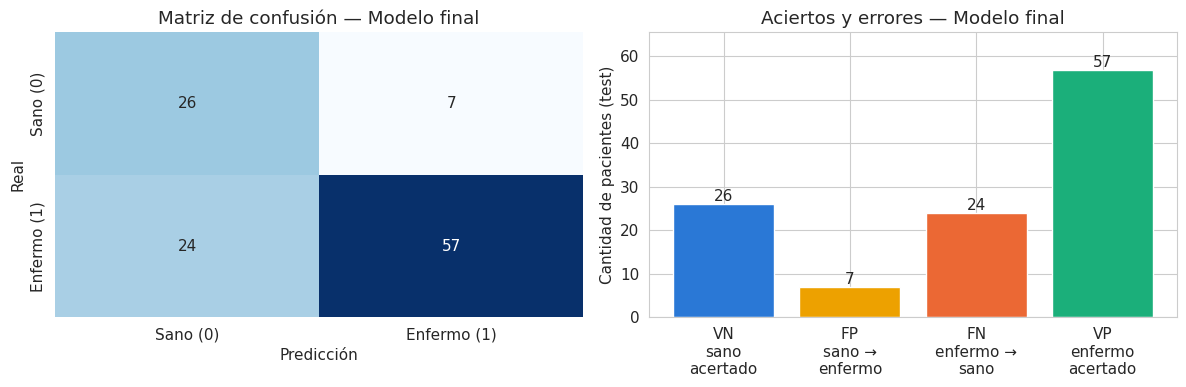

  FN (enfermo NO detectado, el error más grave): 24
  FP (sano enviado a más exámenes): 7

              precision    recall  f1-score   support

    Sano (0)      0.520     0.788     0.627        33
 Enfermo (1)      0.891     0.704     0.786        81

    accuracy                          0.728       114
   macro avg      0.705     0.746     0.706       114
weighted avg      0.783     0.728     0.740       114



In [ ]:
# F.5  Selección del modelo final: el de mayor F1 macro en VALIDACIÓN CRUZADA
# (se elige con CV y no con test, para que el test siga siendo una evaluación imparcial)
estrategia_final = comparacion_balanceo['F1 macro (CV)'].idxmax()
modelo_final = grids[estrategia_final].best_estimator_
print(f'Modelo final: {NOMBRE_FINAL} + {estrategia_final}')
print(f'Hiperparámetros: {grids[estrategia_final].best_params_}\n')
metrics_final = eval_classifier(modelo_final, X_train, y_train, X_test, y_test, 'Modelo final')

### F.6 Ajuste del umbral de decisión (criterio clínico)

Con `class_weight='balanced'` el modelo reconoce a muchos más sanos, pero en test deja pasar a **24 de 81 enfermos** (recall de enfermo 0.70). En un tamizaje ese error es el más costoso. Sin reentrenar, se puede **bajar el umbral**: por defecto se predice "enfermo" si P ≥ 0.5; con un umbral menor se detectan más enfermos a cambio de más falsas alarmas (es el trade-off que se vio en E.4).

Para no "hacer trampa" con el test, el umbral se elige **solo con train**, usando las probabilidades *fuera de fold* de la validación cruzada (`cross_val_predict`). Se toma el umbral más alto que garantiza un **recall de enfermo ≥ 80 %**. Con objetivos de 85–90 % el recall de sano en CV cae a 0.25–0.31 y el F1 macro no mejora, así que 80 % es un compromiso razonable.

In [ ]:
# F.6  Umbral clínico elegido SOLO con train (probabilidades "fuera de fold")
# cross_val_predict entrena 5 veces y predice cada paciente de train con un modelo que NO lo vio
proba_oof = cross_val_predict(modelo_final, X_train, y_train, cv=skf, method='predict_proba')[:, 1]

umbrales = np.round(np.arange(0.05, 0.951, 0.005), 3)
filas = []
for objetivo in [0.75, 0.80, 0.85, 0.90]:
    # el umbral MÁS ALTO que todavía consigue ese recall de enfermo en train (OOF)
    validos = [u for u in umbrales if recall_score(y_train, proba_oof >= u) >= objetivo]
    u = max(validos)
    filas.append({'Recall enfermo mínimo': objetivo, 'Umbral': u,
                  'Recall sano (OOF)': recall_score(y_train, proba_oof >= u, pos_label=0),
                  'F1 macro (OOF)': f1_score(y_train, proba_oof >= u, average='macro')})
tabla_umbral = pd.DataFrame(filas).round(3)
display(tabla_umbral)

RECALL_MINIMO = 0.80
UMBRAL = float(tabla_umbral.loc[tabla_umbral['Recall enfermo mínimo'] == RECALL_MINIMO, 'Umbral'].iloc[0])
print(f'Umbral elegido: {UMBRAL}  (recall de enfermo ≥ {RECALL_MINIMO:.0%} en validación cruzada)')

,Recall enfermo mínimo,Umbral,Recall sano (OOF),F1 macro (OOF)
0,0.75,0.380,0.496,0.621
1,0.80,0.350,0.366,0.588
2,0.85,0.325,0.313,0.595
3,0.90,0.290,0.252,0.578


Umbral elegido: 0.35  (recall de enfermo ≥ 80% en validación cruzada)


,Accuracy,F1 macro,Recall (enfermo),Recall (sano),FN,FP
Umbral 0.5,0.728,0.706,0.704,0.788,24.0,7.0
Umbral clínico (0.35),0.746,0.675,0.852,0.485,12.0,17.0


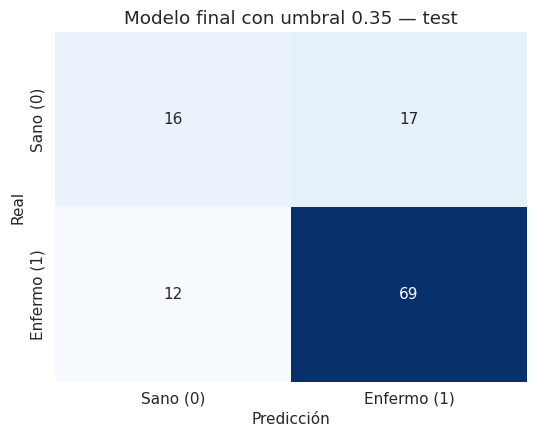

In [ ]:
# F.7  Evaluación en test: umbral 0.5 vs umbral clínico
def metricas_umbral(y_true, proba, u):
    '''Métricas de test al clasificar como enfermo si P(enfermo) >= u.'''
    y_pred = (proba >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {'Accuracy': accuracy_score(y_true, y_pred), 'F1 macro': f1_score(y_true, y_pred, average='macro'),
            'Recall (enfermo)': recall_score(y_true, y_pred),
            'Recall (sano)': recall_score(y_true, y_pred, pos_label=0), 'FN': fn, 'FP': fp}

proba_test = modelo_final.predict_proba(X_test)[:, 1]
comparacion_umbral = pd.DataFrame({
    'Umbral 0.5': metricas_umbral(y_test, proba_test, 0.5),
    f'Umbral clínico ({UMBRAL})': metricas_umbral(y_test, proba_test, UMBRAL),
}).T.round(3)
display(comparacion_umbral)

# Matriz de confusión del modelo final con el umbral clínico
cm = confusion_matrix(y_test, (proba_test >= UMBRAL).astype(int))
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES)
plt.title(f'Modelo final con umbral {UMBRAL} — test')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

In [ ]:
# F.8  Serialización con joblib: Pipeline COMPLETO (preprocesamiento + modelo) + umbral
# Guardar el pipeline entero asegura que un paciente nuevo reciba exactamente el mismo
# preprocesamiento (mediana, log, escalado, one-hot) aprendido en el entrenamiento.
RUTA_MODELO = 'modelo_ilpd_final.joblib'
paquete = {
    'pipeline': modelo_final,
    'umbral': UMBRAL,
    'columnas': list(X.columns),
    'descripcion': f'{NOMBRE_FINAL} + {estrategia_final}; 1 = enfermo, 0 = sano',
}
joblib.dump(paquete, RUTA_MODELO)
print(f'✓ Modelo guardado en {RUTA_MODELO} ({os.path.getsize(RUTA_MODELO) / 1024:.1f} KB)')

✓ Modelo guardado en modelo_ilpd_final.joblib (5.7 KB)


In [ ]:
# F.9  Carga del modelo serializado y predicción sobre nuevos datos
cargado = joblib.load(RUTA_MODELO)
modelo_cargado, umbral_cargado = cargado['pipeline'], cargado['umbral']

# Comprobación: el modelo cargado produce exactamente las mismas probabilidades
assert np.allclose(modelo_cargado.predict_proba(X_test), modelo_final.predict_proba(X_test))
print(f"✓ Modelo cargado: {cargado['descripcion']} | umbral = {umbral_cargado}\n")

# Pacientes FICTICIOS, solo ilustrativos (no son personas reales ni casos clínicos)
nuevos = pd.DataFrame([
    # valores dentro de rangos normales
    {'age': 35, 'gender': 'Female', 'tot_bilirubin': 0.7, 'direct_bilirubin': 0.2,
     'alkphos': 180, 'sgpt': 22, 'sgot': 25, 'tot_proteins': 7.0, 'albumin': 4.0, 'ag_ratio': 1.33},
    # bilirrubinas y enzimas muy elevadas, albúmina baja
    {'age': 52, 'gender': 'Male', 'tot_bilirubin': 6.5, 'direct_bilirubin': 3.2,
     'alkphos': 520, 'sgpt': 140, 'sgot': 260, 'tot_proteins': 6.0, 'albumin': 2.6, 'ag_ratio': 0.76},
    # caso intermedio, valores en el límite
    {'age': 45, 'gender': 'Male', 'tot_bilirubin': 1.1, 'direct_bilirubin': 0.4,
     'alkphos': 240, 'sgpt': 48, 'sgot': 52, 'tot_proteins': 6.6, 'albumin': 3.3, 'ag_ratio': 1.0},
], index=['Paciente ficticio A', 'Paciente ficticio B', 'Paciente ficticio C'])[cargado['columnas']]

prob = modelo_cargado.predict_proba(nuevos)[:, 1]          # probabilidad de ser enfermo
resultado = nuevos[['age', 'gender', 'tot_bilirubin', 'sgpt', 'sgot', 'albumin']].copy()
resultado['P(enfermo)'] = prob.round(3)
resultado[f'Predicción (umbral {umbral_cargado})'] = np.where(prob >= umbral_cargado,
                                                               'Enfermo', 'Sano')
resultado

✓ Modelo cargado: Regresión Logística + class_weight='balanced'; 1 = enfermo, 0 = sano | umbral = 0.35



,age,gender,tot_bilirubin,sgpt,sgot,albumin,P(enfermo),Predicción (umbral 0.35)
Paciente ficticio A,35,Female,0.7,22,25,4.0,0.238,Sano
Paciente ficticio B,52,Male,6.5,140,260,2.6,0.943,Enfermo
Paciente ficticio C,45,Male,1.1,48,52,3.3,0.544,Enfermo


>**Los tres pacientes son ficticios e ilustrativos.** Sirven para demostrar que el modelo serializado se puede cargar y usar con datos nuevos; **no** constituyen un diagnóstico. Un modelo como este, en el mejor de los casos, apoyaría la decisión de pedir más exámenes, nunca reemplazaría la evaluación médica.

---
## G. Conclusiones

### Resumen de resultados
Tras corregir seis encabezados corridos (verificado con rangos clínicos y con la fórmula A/G), eliminar 13 duplicados y preprocesar dentro de un Pipeline (mediana, log1p, StandardScaler, one-hot), se compararon 5 modelos. Sin balanceo, todos favorecieron a la clase mayoritaria: recall de enfermo de 0.90–1.00, pero recall de sano de solo 0.00–0.30, con accuracy (0.71–0.74) casi igual a la de la línea base (0.711). La **Regresión Logística** se eligió por su AUC (0.716 en CV; 0.813 en test), su bajo sobreajuste y su interpretabilidad. Con `GridSearchCV` (C y penalty) y `class_weight='balanced'` alcanzó en test **F1 macro = 0.706 y AUC = 0.813**, y subió el recall de sano de 0.27 a 0.79. Con el **umbral clínico de 0.35**, elegido solo con train, el recall de enfermo vuelve a **0.85** (los falsos negativos bajan de 24 a 12) a cambio de un recall de sano de 0.48. El pipeline completo y el umbral se serializaron con `joblib` y se cargaron para predecir sobre pacientes ficticios.

### Lecciones aprendidas
- **Revisar los datos antes de modelar:** el CSV se leía "bien", pero seis columnas tenían el nombre equivocado; solo la comparación con rangos clínicos lo reveló.
- **La accuracy no basta con clases desbalanceadas:** un modelo que dice siempre "enfermo" logra 71 %. El F1 macro, el AUC y la matriz de confusión cuentan la historia real.
- **Todo lo que aprende de los datos va dentro del Pipeline** (imputación, escalado, SMOTE), para evitar el *data leakage* en la validación cruzada.
- **Balancear es un trade-off, no una mejora gratuita:** gana recall de sano y pierde recall de enfermo. El umbral permite elegir el punto de operación según el costo de cada error.
- **Las decisiones se toman con validación cruzada, no con el test:** con 114 pacientes, el test varía mucho (AUC de LR: 0.72 en CV y 0.81 en test).

### Limitaciones
- **Tamaño pequeño:** 570 registros únicos y solo 33 sanos en test; las métricas de test tienen alta varianza.
- **Una sola región** (noreste de Andhra Pradesh, India) y un solo origen: el modelo no es generalizable sin validación externa.
- **Sin variable de causa:** ILPD no registra consumo de alcohol, hepatitis viral ni otras causas; tampoco antecedentes, medicamentos ni imágenes.
- **Etiqueta poco documentada:** "no paciente" no garantiza un hígado sano; además hay 3 filas con bilirrubina directa mayor que la total (posibles errores de registro).
- **Desbalance:** ninguna estrategia logra a la vez alto recall de enfermo y alto recall de sano (AUC ≈ 0.72 en CV).
- **No sustituye un diagnóstico médico:** es un ejercicio académico de apoyo a la decisión.

### Posibles mejoras
- Validar con un dataset externo (otra región u otro hospital) y con más pacientes sanos.
- Probar modelos de *boosting* (Gradient Boosting, XGBoost) y calibración de probabilidades.
- Crear variables clínicas (cociente AST/ALT o De Ritis, globulina = TP − ALB) y reducir redundancia (bilirrubina total vs directa).
- Usar validación cruzada repetida o anidada para estimar mejor la variabilidad.
- Incorporar variables de causa (consumo de alcohol, marcadores virales) si se dispone de ellas.

### Concientización: el alcohol y el hígado
El consumo nocivo de alcohol es una de las principales causas de enfermedad hepática. Avanza desde el **hígado graso** hacia la **hepatitis alcohólica** y la **cirrosis**, muchas veces sin síntomas hasta etapas avanzadas, por eso son importantes los exámenes de función hepática como los de este dataset. Según la OMS, en 2019 se atribuyeron al alcohol **2,6 millones de muertes** en el mundo, unos 2 millones de ellas en hombres ([OMS, 2024](https://www.who.int/news/item/25-06-2024-over-3-million-annual-deaths-due-to-alcohol-and-drug-use-majority-among-men)). **Importante:** ILPD no registra si los pacientes consumían alcohol, así que este notebook **no permite concluir** que la enfermedad de estos pacientes se deba al alcohol. El mensaje es de contexto y prevención: reducir el consumo y hacerse controles a tiempo protege el hígado.